# Where will this taxi stop?
## Prefix Fréchet kNN + Unit-Disk Graph Cliques on 1.2 million Porto taxi trips

**The idea in 4 steps**
1. **Fréchet kNN**: compare the first part of a taxi trip with all 1.2 million old trips using the
   *prefix discrete Fréchet distance*, and take the 20 most similar old trips.
2. **Offset**: each old trip says "from the point that matches where we are now, I still drove *this* much further".
3. **Graph**: the 20 guesses become points; join two points if they are closer than *r* km
   (a **unit-disk graph**); the biggest group where everybody agrees with everybody is the
   **maximum clique**; its centre is our answer.
4. **Machine learning**: gradient boosting and a Random Forest get normal trip features,
   with and without the Fréchet/graph features, and predict **how far the taxi still goes**.

**How to run:** put `train.csv` (ECML/PKDD 2015 taxi data, UCI dataset 339) in a folder `porto/`
and press *Run All*. About 30 minutes; the neighbour search is saved in `cache/`, so a second run is faster.
Every picture is saved in `figures/`.

## 1. Settings

In [1]:
import os, json, time, math, pickle, warnings, textwrap
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from numba import njit
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

CSV           = "porto/train.csv"
N_TEST_TRIPS  = 10_000     # clean test trips (each cut at 25%, 50%, 75% and at one random point)
N_ABLATION    = 500        # test trips also searched with DTW and lock-step (slower distances)
N_NOISY_TEST  = 2_000      # extra test trips that have a GPS glitch (robustness check)
N_VAL         = 40_000     # training prefixes with Fréchet features (choose r, train the models)
N_BIG         = 500_000    # training prefixes for the "normal features only" model (no Fréchet search needed)
N_TUNE        = 10_000     # of the N_VAL prefixes, used to choose the graph radius r
FRACTIONS     = [0.25, 0.5, 0.75]
RANDOM_CUT    = (0.10, 0.90)
K             = 20         # number of neighbours
R_GRID        = [0.25, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8]   # graph radii (km) tried on validation
LC_SIZES      = [10_000, 20_000, 40_000, 100_000, 250_000, 500_000]
MODEL_SEEDS   = [0, 1, 2]
N_SPEED       = 200        # questions timed one by one
PRACTICAL_M   = 25         # gains below 25 m are called "negligible"
N_BOOT        = 1000       # bootstrap repeats
N_THREADS     = os.cpu_count() or 4
CHUNK         = 32         # questions per job in the parallel search
SEED          = 0

MIN_LEN, MAX_LEN = 12, 240 # trips of 3 min .. 1 hour (one GPS point every 15 s)
MAX_STEP_KM   = 0.6        # a jump > 0.6 km in 15 s is a GPS error
TEST_SHARE    = 0.15       # the newest 15% of trips are the test pool
LON0, LAT0    = -8.61, 41.15
EARTH_KM      = 6371.0088
DEG           = math.pi / 180

def stream(k):
    """A separate random stream per purpose, so every run (with or without cache) gives the same numbers."""
    return np.random.default_rng([SEED, k])

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 12,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "legend.fontsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)
T_START = time.time()

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

FIXED    = ["25%", "50%", "75%"]
SETTINGS = FIXED + ["random"]
SAW = {"25%": "saw 25% of the trip", "50%": "saw 50% of the trip", "75%": "saw 75% of the trip",
       "random": "random cut point (10–90%)"}

def nearest_fixed(frac):
    return FIXED[int(np.argmin([abs(frac - f) for f in FRACTIONS]))]

BEST, NO_GRAPH, BIG = "GBM + Fréchet + graph features", "GBM + Fréchet features (no graph)", "GBM (normal features, big data)"
NICE = {"stay (current point)": "Stay: it stops where it is now",
        "prefix-DFD (mean)": "Fréchet neighbours: plain average",
        "prefix-DFD + offset": "Fréchet + offset",
        "prefix-DFD + offset + graph": "Fréchet + offset + graph (clique)",
        "RF (normal features)": "Random Forest: normal features",
        "RF + Fréchet + graph features": "Random Forest + Fréchet + graph",
        "GBM (normal features)": "Boosting: normal features",
        BIG: "Boosting: normal features, big data",
        NO_GRAPH: "Boosting + Fréchet, no graph",
        BEST: "Boosting + Fréchet + graph",
        "full DFD (mean)": "Full Fréchet (whole old trip)",
        "prefix DTW (mean)": "DTW (adds distances)",
        "lock-step (mean)": "Lock-step (no waiting)"}
COLOR = {"stay (current point)": "#9e9e9e", "prefix-DFD (mean)": "#6baed6", "prefix-DFD + offset": "#4292c6",
         "prefix-DFD + offset + graph": "#41ab5d", "RF (normal features)": "#d1c4e9",
         "RF + Fréchet + graph features": "#238b45", "GBM (normal features)": "#b39ddb", BIG: "#7e57c2",
         NO_GRAPH: "#74c476", BEST: "#00441b", "full DFD (mean)": "#fdae6b", "prefix DTW (mean)": "#fd8d3c",
         "lock-step (mean)": "#e6550d"}

## 2. Load and clean the trips
* drop trips with missing GPS points, shorter than 3 min or longer than 1 hour;
* trips with a GPS jump are not used for learning; some of the newest ones form an extra *noisy* test set;
* (longitude, latitude) → (x, y) in km around Porto centre, so distance = Pythagoras
  (checked against the exact Haversine distance at the end);
* **split by time**: the oldest 85% of trips are the history we learn from, test trips come from the newest 15%.

In [2]:
def gps_string_to_km(s):
    a = np.asarray(json.loads(s), dtype=np.float64)
    if a.ndim != 2 or len(a) == 0:
        return None
    x = (a[:, 0] - LON0) * DEG * EARTH_KM * math.cos(LAT0 * DEG)
    y = (a[:, 1] - LAT0) * DEG * EARTH_KM
    return np.column_stack([x, y])

def km_to_gps(x, y):
    return LON0 + x / (EARTH_KM * math.cos(LAT0 * DEG)) / DEG, LAT0 + y / EARTH_KM / DEG

def check_trip(xy):
    """'good', 'noisy' (has a GPS jump) or None (unusable)."""
    if xy is None or not (MIN_LEN <= len(xy) <= MAX_LEN) or np.abs(xy).max() >= 40:
        return None
    if np.linalg.norm(np.diff(xy, axis=0), axis=1).max() > MAX_STEP_KM:
        return "noisy"
    return "good"

assert os.path.exists(CSV), "put train.csv in the folder porto/"
t0 = time.time()
trips, info, noisy_trips, noisy_info, n_read = [], [], [], [], 0
for chunk in pd.read_csv(CSV, usecols=["CALL_TYPE", "TIMESTAMP", "MISSING_DATA", "POLYLINE"], chunksize=200_000):
    n_read += len(chunk)
    chunk = chunk[chunk["MISSING_DATA"].astype(str) == "False"]
    for call, stamp, s in zip(chunk["CALL_TYPE"].values, chunk["TIMESTAMP"].values, chunk["POLYLINE"].values):
        xy = gps_string_to_km(s)
        kind = check_trip(xy)
        if kind == "good":
            trips.append(xy); info.append((call, stamp))
        elif kind == "noisy":
            noisy_trips.append(xy); noisy_info.append((call, stamp))

def add_time_columns(rows):
    df = pd.DataFrame(rows, columns=["call_type", "timestamp"])
    when = pd.to_datetime(df["timestamp"], unit="s")
    df["hour"] = (when.dt.hour + when.dt.minute / 60).values
    df["weekday"] = when.dt.day_of_week.values
    return df

info, noisy_info = add_time_columns(info), add_time_columns(noisy_info)

def meta_of(df, i):
    """(hour, weekday, call type) of trip i."""
    return (float(df["hour"].values[i]), int(df["weekday"].values[i]), str(df["call_type"].values[i]))

rng = np.random.default_rng(SEED)                       # used only for the test split
by_time = np.argsort(info["timestamp"].values, kind="stable")
n_train = int(len(by_time) * (1 - TEST_SHARE))
train_ids, test_pool = by_time[:n_train], by_time[n_train:]
test_ids = rng.choice(test_pool, size=min(N_TEST_TRIPS, len(test_pool)), replace=False)
ablation_ids = set(test_ids[:min(N_ABLATION, len(test_ids))].tolist())
T_SPLIT = info["timestamp"].values[test_pool].min()
noisy_pool = np.flatnonzero(noisy_info["timestamp"].values >= T_SPLIT)
noisy_ids = rng.choice(noisy_pool, size=min(N_NOISY_TEST, len(noisy_pool)), replace=False)
print(f"read {n_read:,} rows in {time.time()-t0:.0f}s | kept {len(trips):,} clean trips | train {len(train_ids):,} | "
      f"test {len(test_ids):,} | noisy test {len(noisy_ids):,}")

read 1,710,670 rows in 78s | kept 1,438,874 clean trips | train 1,223,042 | test 10,000 | noisy test 2,000


## 3. Look at the data: routes, destinations, trip lengths

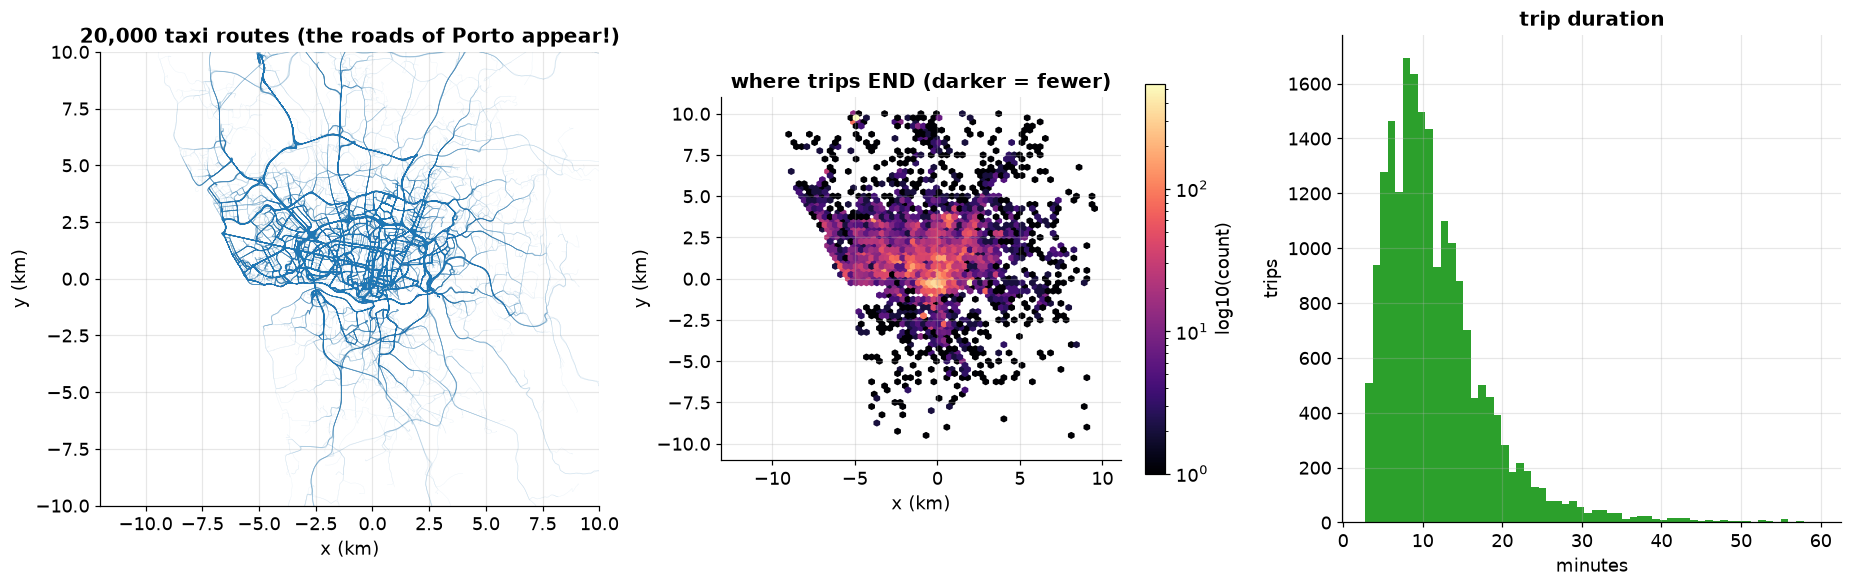

In [3]:
show = stream(1).choice(train_ids, size=min(20_000, len(train_ids)), replace=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
ax[0].add_collection(LineCollection([trips[i] for i in show], linewidths=0.3, alpha=0.08, colors="tab:blue"))
ax[0].set_xlim(-12, 10); ax[0].set_ylim(-10, 10); ax[0].set_aspect("equal")
ax[0].set_title(f"{len(show):,} taxi routes (the roads of Porto appear!)")
ends = np.array([trips[i][-1] for i in show])
hb = ax[1].hexbin(ends[:, 0], ends[:, 1], gridsize=70, bins="log", cmap="magma", extent=(-12, 10, -10, 10))
ax[1].set_aspect("equal"); ax[1].set_title("where trips END (darker = fewer)")
fig.colorbar(hb, ax=ax[1], shrink=0.8, label="log10(count)")
minutes = np.array([(len(trips[i]) - 1) * 15 / 60 for i in show])
ax[2].hist(minutes, bins=60, color="tab:green"); ax[2].set_title("trip duration")
ax[2].set_xlabel("minutes"); ax[2].set_ylabel("trips")
for a in ax[:2]:
    a.set_xlabel("x (km)"); a.set_ylabel("y (km)")
plt.tight_layout(); save(fig, "01_data_overview")

## 4. Pack the training trips into flat arrays, with a grid on the start points
`XY` = all points of all training trips one after another; trip `c` is `XY[OFF[c]:OFF[c+1]]`.
Every training trip is filed under the 100 m × 100 m grid cell of its **start point**; a search visits the
cells in rings around the new trip's start. Every start in ring $t$ is at least $(t-1)\cdot 100$ m away, so
as soon as that is more than the current K-th best distance, rule **L1** stops the search.

In [4]:
def start_cell(starts, g0=-40.0, gsize=0.1):
    gn = int(math.ceil(-2 * g0 / gsize))
    ix = np.clip(((starts[:, 0] - g0) / gsize).astype(np.int64), 0, gn - 1)
    iy = np.clip(((starts[:, 1] - g0) / gsize).astype(np.int64), 0, gn - 1)
    return ix * gn + iy

# trips of one grid cell lie next to each other in memory (faster search, same answers)
train_ids = train_ids[np.argsort(start_cell(np.array([trips[i][0] for i in train_ids])), kind="stable")]
train_trips = [trips[i] for i in train_ids]
OFF = np.zeros(len(train_trips) + 1, np.int64)
OFF[1:] = np.cumsum([len(t) for t in train_trips])
XY = np.ascontiguousarray(np.concatenate(train_trips))
STARTS = np.ascontiguousarray([t[0] for t in train_trips])
ENDS = np.array([t[-1] for t in train_trips])
BOXES = np.ascontiguousarray([[t[:, 0].min(), t[:, 0].max(), t[:, 1].min(), t[:, 1].max()] for t in train_trips])
N_TRAIN = len(train_trips)

def build_grid(starts, g0=-40.0, gsize=0.1):
    gn = int(math.ceil(-2 * g0 / gsize))
    cell = start_cell(starts, g0, gsize)
    cell_start = np.zeros(gn * gn + 1, np.int64)
    cell_start[1:] = np.cumsum(np.bincount(cell, minlength=gn * gn))
    return cell_start, np.argsort(cell, kind="stable").astype(np.int64), g0, gsize, gn

CELL_START, CELL_TRIPS, G0, GSIZE, GN = build_grid(STARTS)
print(f"{N_TRAIN:,} training trips, {len(XY):,} GPS points, {XY.nbytes/1e9:.2f} GB | "
      f"grid {GN}×{GN} cells of {GSIZE*1000:.0f} m, busiest cell holds {np.diff(CELL_START).max():,} starts")

1,223,042 training trips, 58,889,386 GPS points, 0.94 GB | grid 800×800 cells of 100 m, busiest cell holds 67,417 starts


## 5. The engine: Fréchet distance with dynamic programming
Two walkers, one on the new route $P=(p_1..p_n)$ and one on an old route $Q=(q_1..q_m)$, joined by a
leash; each step one or both move forward. The cost of a walk is its **longest leash**; $d_F(P,Q)$ = the
smallest possible cost:

$$D[i][j] = \max\big(\|p_i-q_j\|,\ \min(D[i-1][j],\ D[i][j-1],\ D[i-1][j-1])\big)$$

**Prefix version** (our idea): $d_{pre}(P,Q)=\min_j D[n][j]$, the best cell of the **last row**;
its column $j^*$ is where on $Q$ we are "now". Four distances (`mode`): 0 prefix Fréchet (ours),
1 full Fréchet, 2 prefix DTW (sum instead of max), 3 lock-step (no waiting).

**Exact pruning** (lower bounds; a trip is skipped only when a bound proves it cannot be among the K nearest):
* **L1** start points: $d \ge \|p_1-q_1\|$;
* **L2** bounding box: $d \ge \max_i \mathrm{dist}(p_i, \mathrm{box}(Q))$ (full Fréchet also $d \ge \|p_n-q_m\|$);
* **L4** 'now' point (prefix Fréchet): $d_{pre} \ge \min_j \|p_n-q_j\|$;
* **L3** DP values never go down along a walk, so cells above the current K-th best distance $\varepsilon$ are
  blocked; if a whole row is blocked, $d > \varepsilon$. The answer is exact whenever $d \le \varepsilon$.

The nearest rings (≥ 256 trips) are checked first, sorted by a cheap lower bound, so the K-th best distance
shrinks fast. `@njit` (numba) compiles the loops to machine code and lets all CPU cores work at once.

In [5]:
PREFIX_DFD, FULL_DFD, PREFIX_DTW, LOCKSTEP = 0, 1, 2, 3
MODE_NAMES = {PREFIX_DFD: "prefix-DFD", FULL_DFD: "full DFD", PREFIX_DTW: "prefix DTW", LOCKSTEP: "lock-step"}
SEED_CAP = 256

@njit(cache=True, nogil=True)
def point_dist(ax, ay, bx, by):
    return math.sqrt((ax - bx) ** 2 + (ay - by) ** 2)

@njit(cache=True, nogil=True)
def curve_distance(P, Q, mode, eps):
    """Distance between P and Q, and j* (index on Q matched with the last point of P).
    Exact if the distance is <= eps; otherwise (inf, -1). Cells > eps are blocked (rule L3)."""
    n, m = P.shape[0], Q.shape[0]
    if mode == LOCKSTEP:                       # point i with point i, no waiting
        if m < n:
            return np.inf, -1
        worst = 0.0
        for i in range(n):
            worst = max(worst, point_dist(P[i, 0], P[i, 1], Q[i, 0], Q[i, 1]))
            if worst > eps:
                return np.inf, -1
        return worst, n - 1
    use_sum = mode == PREFIX_DTW
    prev = np.empty(m)                         # two rows of the DP table
    cur = np.empty(m)
    acc, plo, phi = 0.0, 0, -1                 # open cells of the previous row: plo..phi
    for j in range(m):                         # row 0: walk along Q only
        c = point_dist(P[0, 0], P[0, 1], Q[j, 0], Q[j, 1])
        v = acc + c if use_sum else max(acc, c)
        if v > eps:
            break
        prev[j] = v; acc = v; phi = j
    if phi < 0:
        return np.inf, -1
    for i in range(1, n):
        lo, hi, left, j = -1, -1, np.inf, plo
        while j < m:
            b = left                                           # D[i][j-1]
            if j <= phi and prev[j] < b:                       # D[i-1][j]
                b = prev[j]
            if plo <= j - 1 <= phi and prev[j - 1] < b:        # D[i-1][j-1]
                b = prev[j - 1]
            if b == np.inf:
                if j > phi:                                    # nothing can open any more in this row
                    break
                cur[j] = np.inf; left = np.inf; j += 1
                continue
            c = point_dist(P[i, 0], P[i, 1], Q[j, 0], Q[j, 1])
            v = b + c if use_sum else max(b, c)
            if v > eps:
                cur[j] = np.inf; left = np.inf
            else:
                cur[j] = v; left = v
                if lo < 0:
                    lo = j
                hi = j
            j += 1
        if lo < 0:                                             # the whole row is blocked (L3)
            return np.inf, -1
        prev, cur = cur, prev
        plo, phi = lo, hi
    if mode == FULL_DFD:                                       # whole Q: the corner cell
        return (prev[m - 1], m - 1) if phi == m - 1 else (np.inf, -1)
    best, bj = np.inf, -1                                      # prefix: best cell of the last row
    for j in range(plo, phi + 1):
        if prev[j] < best:
            best, bj = prev[j], j
    return best, bj

@njit(cache=True, nogil=True)
def box_dist(P, i, BOXES, c):
    dx = max(BOXES[c, 0] - P[i, 0], 0.0, P[i, 0] - BOXES[c, 1])
    dy = max(BOXES[c, 2] - P[i, 1], 0.0, P[i, 1] - BOXES[c, 3])
    return math.sqrt(dx * dx + dy * dy)

@njit(cache=True, nogil=True)
def to_curve(P, i, XY, OFF, c):
    """Distance from P[i] to the nearest point of old trip c."""
    best = np.inf
    for t in range(OFF[c], OFF[c + 1]):
        dd = (P[i, 0] - XY[t, 0]) ** 2 + (P[i, 1] - XY[t, 1]) ** 2
        if dd < best:
            best = dd
    return math.sqrt(best)

@njit(cache=True, nogil=True)
def lower_bound(P, c, ls, mode, BOXES, XY, OFF):
    """The full L1 + L2 lower bound (+ end point for full DFD, + L4 for prefix DFD)."""
    lb, total = ls, 0.0
    for i in range(P.shape[0]):
        to_box = box_dist(P, i, BOXES, c)
        if mode == PREFIX_DTW:
            total += to_box
        else:
            lb = max(lb, to_box)
    if mode == PREFIX_DTW:
        lb = max(lb, total)
    if mode == FULL_DFD:
        e = OFF[c + 1] - 1
        lb = max(lb, point_dist(P[-1, 0], P[-1, 1], XY[e, 0], XY[e, 1]))
    if mode == PREFIX_DFD:
        lb = max(lb, to_curve(P, P.shape[0] - 1, XY, OFF, c))
    return lb

@njit(cache=True, nogil=True)
def pruned_by_bounds(P, c, ls, mode, BOXES, XY, OFF, kth):
    """True if L1/L2 prove d > kth. Stops as soon as it knows (point 'now' first, then a coarse pass)."""
    n = P.shape[0]
    if ls > kth:
        return True
    if mode == FULL_DFD:
        e = OFF[c + 1] - 1
        if point_dist(P[n - 1, 0], P[n - 1, 1], XY[e, 0], XY[e, 1]) > kth:
            return True
    if mode == PREFIX_DTW:
        total = 0.0
        for i in range(n):
            total += box_dist(P, i, BOXES, c)
            if total > kth:
                return True
        return False
    if box_dist(P, n - 1, BOXES, c) > kth:
        return True
    step = max(1, n // 8)
    for i in range(n - 1 - step, -1, -step):
        if box_dist(P, i, BOXES, c) > kth:
            return True
    for i in range(n):
        if box_dist(P, i, BOXES, c) > kth:
            return True
    if mode == PREFIX_DFD and to_curve(P, n - 1, XY, OFF, c) > kth:      # L4
        return True
    return False

@njit(cache=True, nogil=True)
def knn_query(P, k, mode, skip, XY, OFF, STARTS, BOXES, CELL_START, CELL_TRIPS, G0, GSIZE, GN,
              out_c, out_d, out_j, stats):
    """Exact k nearest old trips of P. stats = [looked at (passed L1), removed by L2, DP started, DP stopped by L3]."""
    best_d = np.full(k, np.inf); best_c = np.full(k, -1); best_j = np.full(k, -1)
    kth = np.inf
    px, py = P[0, 0], P[0, 1]
    cx = min(max(int((px - G0) / GSIZE), 0), GN - 1)
    cy = min(max(int((py - G0) / GSIZE), 0), GN - 1)
    # ---- phase 1: all trips of the nearest rings (>= SEED_CAP trips), best lower bound first
    buf = np.empty(4 * SEED_CAP, np.int64)
    nb, R = 0, -1
    for r in range(GN):
        if nb >= SEED_CAP or (cx - r < 0 and cy - r < 0 and cx + r >= GN and cy + r >= GN):
            break
        for ix in range(cx - r, cx + r + 1):
            if ix < 0 or ix >= GN:
                continue
            edge = ix == cx - r or ix == cx + r
            iy = cy - r
            while iy <= cy + r:
                if 0 <= iy < GN:
                    cell = ix * GN + iy
                    cnt = CELL_START[cell + 1] - CELL_START[cell]
                    if nb + cnt > buf.shape[0]:
                        bigger = np.empty(2 * (nb + cnt), np.int64)
                        bigger[:nb] = buf[:nb]
                        buf = bigger
                    for t in range(CELL_START[cell], CELL_START[cell + 1]):
                        buf[nb] = CELL_TRIPS[t]; nb += 1
                iy += 1 if (edge or r == 0) else 2 * r
        R = r
    keys, lss = np.empty(nb), np.empty(nb)
    for t in range(nb):                                    # cheap lower bound = sort key
        c = buf[t]
        lss[t] = point_dist(px, py, STARTS[c, 0], STARTS[c, 1])
        keys[t] = max(lss[t], box_dist(P, P.shape[0] - 1, BOXES, c))
        if mode == FULL_DFD:                               # + end point (O(1))
            e = OFF[c + 1] - 1
            keys[t] = max(keys[t], point_dist(P[-1, 0], P[-1, 1], XY[e, 0], XY[e, 1]))
    order = np.argsort(keys)
    for t in range(nb):
        q = order[t]
        c = buf[q]
        if c == skip:
            continue
        if keys[q] > kth:                                  # sorted: all the rest are pruned too
            for u in range(t, nb):
                if buf[order[u]] != skip and lss[order[u]] <= kth:
                    stats[0] += 1; stats[1] += 1
            break
        stats[0] += 1
        if pruned_by_bounds(P, c, lss[q], mode, BOXES, XY, OFF, kth):   # L2 (+ L4)
            stats[1] += 1
            continue
        stats[2] += 1
        d, j = curve_distance(P, XY[OFF[c]:OFF[c + 1]], mode, kth)
        if d == np.inf:
            stats[3] += 1
            continue
        if d < kth:
            w = np.argmax(best_d)
            best_d[w], best_c[w], best_j[w] = d, c, j
            kth = best_d.max()
    # ---- phase 2: the outer rings, until rule L1 stops the search
    for r in range(R + 1, GN):
        if r >= 2 and (r - 1) * GSIZE > kth:
            break
        if cx - r < 0 and cy - r < 0 and cx + r >= GN and cy + r >= GN:
            break
        for ix in range(cx - r, cx + r + 1):
            if ix < 0 or ix >= GN:
                continue
            edge = ix == cx - r or ix == cx + r
            iy = cy - r
            while iy <= cy + r:
                if 0 <= iy < GN:
                    cell = ix * GN + iy
                    for t in range(CELL_START[cell], CELL_START[cell + 1]):
                        c = CELL_TRIPS[t]
                        if c == skip:
                            continue
                        ls = point_dist(px, py, STARTS[c, 0], STARTS[c, 1])
                        if ls > kth:                                 # L1
                            continue
                        stats[0] += 1
                        if pruned_by_bounds(P, c, ls, mode, BOXES, XY, OFF, kth):   # L2
                            stats[1] += 1
                            continue
                        stats[2] += 1
                        d, j = curve_distance(P, XY[OFF[c]:OFF[c + 1]], mode, kth)  # L3
                        if d == np.inf:
                            stats[3] += 1
                            continue
                        if d < kth:
                            w = np.argmax(best_d)
                            best_d[w], best_c[w], best_j[w] = d, c, j
                            kth = best_d.max()
                iy += 1 if (edge or r == 0) else 2 * r
    o = np.argsort(best_d)
    for t in range(k):
        out_c[t], out_d[t], out_j[t] = best_c[o[t]], best_d[o[t]], best_j[o[t]]

@njit(cache=True, nogil=True)
def knn_chunk(lo, hi, QXY, QOFF, SKIP, k, mode, XY, OFF, STARTS, BOXES, CELL_START, CELL_TRIPS, G0, GSIZE, GN,
              OUT_C, OUT_D, OUT_J, STATS):
    for q in range(lo, hi):
        knn_query(QXY[QOFF[q]:QOFF[q + 1]], k, mode, SKIP[q], XY, OFF, STARTS, BOXES, CELL_START, CELL_TRIPS,
                  G0, GSIZE, GN, OUT_C[q], OUT_D[q], OUT_J[q], STATS[q])

def search(prefixes, skips, mode, k, label=None, db=None):
    """Exact k nearest old trips for many prefixes at once, on all CPU cores."""
    xy, off, starts, boxes, cs, ct, g0, gs, gn = db or (XY, OFF, STARTS, BOXES, CELL_START, CELL_TRIPS, G0, GSIZE, GN)
    nq = len(prefixes)
    QOFF = np.zeros(nq + 1, np.int64); QOFF[1:] = np.cumsum([len(p) for p in prefixes])
    QXY = np.ascontiguousarray(np.concatenate(prefixes)) if nq else np.zeros((0, 2))
    SKIP = np.asarray(skips, np.int64)
    C = np.full((nq, k), -1, np.int64); D = np.full((nq, k), np.inf); J = np.full((nq, k), -1, np.int64)
    S = np.zeros((nq, 4), np.int64)
    def job(ch):
        knn_chunk(ch[0], ch[1], QXY, QOFF, SKIP, k, mode, xy, off, starts, boxes, cs, ct, g0, gs, gn, C, D, J, S)
        return ch[1] - ch[0]
    chunks = [(a, min(a + CHUNK, nq)) for a in range(0, nq, CHUNK)]
    t0, done, next_print = time.time(), 0, 0.1
    with ThreadPoolExecutor(N_THREADS) as pool:
        for n_ in pool.map(job, chunks):
            done += n_
            if label and (done >= next_print * nq or done == nq):
                el = time.time() - t0
                print(f"  {label}: {done:,}/{nq:,}  ({el:.0f}s, about {el / done * (nq - done):.0f}s left)")
                next_print += 0.1
    return C, D, J, S

def nearest_trips(P, mode=PREFIX_DFD, skip=-1, k=K):
    """One question, one thread (used for pictures and for the speed measurement)."""
    C = np.full((1, k), -1, np.int64); D = np.full((1, k), np.inf); J = np.full((1, k), -1, np.int64)
    S = np.zeros((1, 4), np.int64)
    knn_chunk(0, 1, np.ascontiguousarray(P), np.array([0, len(P)], np.int64), np.array([skip], np.int64), k, mode,
              XY, OFF, STARTS, BOXES, CELL_START, CELL_TRIPS, G0, GSIZE, GN, C, D, J, S)
    ok = C[0] >= 0
    return C[0][ok], D[0][ok], J[0][ok], S[0]

def first_part(trip, frac):
    n = max(2, int(round(frac * len(trip))))
    return np.ascontiguousarray(trip[:n])

## 6. Check the engine (every lemma is tested)
* **Test 1**: the DP equals the definition (every possible walk listed, tiny curves).
* **Test 2 (Lemma A)**: prefix distance = min over j of the full distance to $Q[1..j]$.
* **Test 3 (L1, L2, L4)**: the lower bounds never exceed the true distance.
* **Test 4 (L3)**: with a limit $\varepsilon$, the DP is exact when $d \le \varepsilon$ and says "too far" otherwise.
* **Test 5 (Lemma C)**: $\|p_n - q_{j^*}\| \le d_{pre}(P,Q)$, so the offset moves a neighbour's guess by at
  most its Fréchet distance.
* **Test 6**: on 2,000 random curves the grid search returns the same K distances as checking every curve.

In [6]:
def all_walks_cost(P, Q, i=0, j=0):
    """Definition, by brute force: the cheapest walk from (i, j) to the end (n-1, m-1)."""
    here = np.linalg.norm(P[i] - Q[j])
    if i == len(P) - 1 and j == len(Q) - 1:
        return here
    options = []
    if i + 1 < len(P): options.append(all_walks_cost(P, Q, i + 1, j))
    if j + 1 < len(Q): options.append(all_walks_cost(P, Q, i, j + 1))
    if i + 1 < len(P) and j + 1 < len(Q): options.append(all_walks_cost(P, Q, i + 1, j + 1))
    return max(here, min(options))

test_rng = np.random.default_rng(42)
def random_curve(n):
    return np.ascontiguousarray(np.cumsum(test_rng.normal(0, 1, (n, 2)), axis=0))

def one_curve_db(Q):
    box = np.array([[Q[:, 0].min(), Q[:, 0].max(), Q[:, 1].min(), Q[:, 1].max()]])
    return box, np.ascontiguousarray(Q), np.array([0, len(Q)], np.int64)

for _ in range(300):                                         # Test 1
    P, Q = random_curve(test_rng.integers(1, 6)), random_curve(test_rng.integers(1, 6))
    assert np.isclose(curve_distance(P, Q, FULL_DFD, np.inf)[0], all_walks_cost(P, Q))
print("Test 1  DP == definition (all walks listed)            ✓")

for _ in range(300):                                         # Test 2
    P, Q = random_curve(test_rng.integers(2, 15)), random_curve(test_rng.integers(2, 25))
    pre, j_star = curve_distance(P, Q, PREFIX_DFD, np.inf)
    fulls = [curve_distance(P, np.ascontiguousarray(Q[:j + 1]), FULL_DFD, np.inf)[0] for j in range(len(Q))]
    assert np.isclose(pre, min(fulls)) and np.isclose(fulls[j_star], pre)
print("Test 2  Lemma A: last-row minimum == min_j d_F          ✓")

for _ in range(500):                                         # Test 3
    P, Q = random_curve(test_rng.integers(2, 15)), random_curve(test_rng.integers(2, 25))
    box, xy1, off1 = one_curve_db(Q)
    ls = np.linalg.norm(P[0] - Q[0])
    for mode in (0, 1, 2, 3):
        d = curve_distance(P, Q, mode, np.inf)[0]
        if d < np.inf:
            assert lower_bound(P, 0, ls, mode, box, xy1, off1) <= d + 1e-9
            for limit in (d * 0.3, d * 0.9, d, d * 1.5):
                if pruned_by_bounds(P, 0, ls, mode, box, xy1, off1, limit):
                    assert d > limit - 1e-9       # (1e-9: rounding of the last digit)
print("Test 3  L1 + L2 + L4 lower bounds <= true distance      ✓")

for _ in range(500):                                         # Test 4
    P, Q = random_curve(test_rng.integers(2, 15)), random_curve(test_rng.integers(2, 25))
    for mode in (0, 1, 2, 3):
        d, jd = curve_distance(P, Q, mode, np.inf)
        for limit in (d * 0.5, d * 0.99, d, d * 1.01, d * 2):
            out, jo = curve_distance(P, Q, mode, limit)
            if d <= limit:
                assert out == d and jo == jd    # exact, same j*, when within the limit
            else:
                assert out == np.inf            # otherwise "too far"
print("Test 4  L3 (cell version): exact within the limit       ✓")

for _ in range(500):                                         # Test 5
    P, Q = random_curve(test_rng.integers(2, 15)), random_curve(test_rng.integers(2, 25))
    pre, j_star = curve_distance(P, Q, PREFIX_DFD, np.inf)
    assert np.linalg.norm(P[-1] - Q[j_star]) <= pre + 1e-9
print("Test 5  Lemma C: |now - matched point| <= d_pre         ✓")

toy = [np.ascontiguousarray(np.cumsum(test_rng.normal(0, 0.15, (int(test_rng.integers(5, 30)), 2)), axis=0)
                            + test_rng.normal(0, 1.5, 2)) for _ in range(2_000)]       # Test 6
toy_off = np.zeros(len(toy) + 1, np.int64); toy_off[1:] = np.cumsum([len(t) for t in toy])
toy_xy = np.ascontiguousarray(np.concatenate(toy)); toy_starts = np.ascontiguousarray([t[0] for t in toy])
toy_boxes = np.ascontiguousarray([[t[:, 0].min(), t[:, 0].max(), t[:, 1].min(), t[:, 1].max()] for t in toy])
toy_db = (toy_xy, toy_off, toy_starts, toy_boxes, *build_grid(toy_starts))
toy_q = [np.ascontiguousarray(t[:max(2, len(t) // 2)]) for t in toy[:40]]
for mode in (0, 1, 2, 3):
    _, D_fast, _, _ = search(toy_q, list(range(40)), mode, 10, db=toy_db)
    for q, P in enumerate(toy_q):
        every = np.sort([curve_distance(P, t, mode, np.inf)[0] for c, t in enumerate(toy) if c != q])[:10]
        assert np.allclose(D_fast[q][D_fast[q] < np.inf], every[every < np.inf])
print("Test 6  grid search == checking every curve (toy data)  ✓")

Test 1  DP == definition (all walks listed)            ✓
Test 2  Lemma A: last-row minimum == min_j d_F          ✓
Test 3  L1 + L2 + L4 lower bounds <= true distance      ✓
Test 4  L3 (cell version): exact within the limit       ✓
Test 5  Lemma C: |now - matched point| <= d_pre         ✓
Test 6  grid search == checking every curve (toy data)  ✓


## 7. Picture: how Fréchet matches two routes
Left: the leash lines of the best walk (red = the longest leash = the distance).
Right: the DP table; the walk is the white path; the last row's best cell is $j^*$.

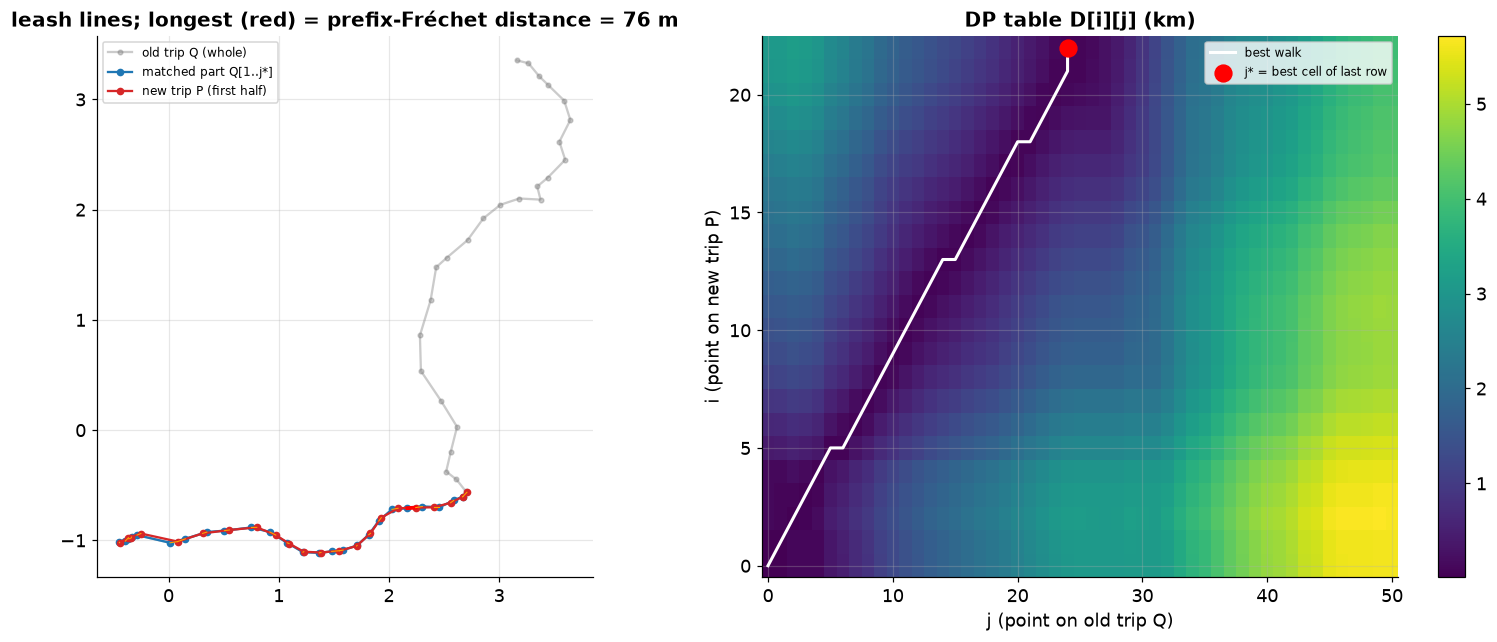

In [7]:
def dp_table(P, Q):
    """Full DP table (slow Python version, only for pictures)."""
    D = np.zeros((len(P), len(Q)))
    for i in range(len(P)):
        for j in range(len(Q)):
            c = np.linalg.norm(P[i] - Q[j])
            if i == 0 and j == 0: D[i, j] = c
            elif i == 0: D[i, j] = max(D[i, j - 1], c)
            elif j == 0: D[i, j] = max(D[i - 1, j], c)
            else: D[i, j] = max(min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1]), c)
    return D

def best_walk(D, j_end):
    """Go back from (n-1, j_end) to (0, 0), always to the smallest neighbour cell."""
    i, j, walk = D.shape[0] - 1, j_end, []
    while True:
        walk.append((i, j))
        if i == 0 and j == 0:
            return walk[::-1]
        steps = [(a, b) for a, b in [(i - 1, j - 1), (i - 1, j), (i, j - 1)] if a >= 0 and b >= 0]
        i, j = min(steps, key=lambda s: D[s])

example_trip = trips[test_ids[0]]
P = first_part(example_trip, 0.5)
c, d, j, _ = nearest_trips(P)
Q = XY[OFF[c[0]]:OFF[c[0] + 1]]
D = dp_table(P, Q)
walk = best_walk(D, j[0])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].plot(Q[:, 0], Q[:, 1], "-o", color="tab:gray", ms=3, alpha=0.4, label="old trip Q (whole)")
ax[0].plot(Q[:j[0] + 1, 0], Q[:j[0] + 1, 1], "-o", color="tab:blue", ms=4, label="matched part Q[1..j*]")
ax[0].plot(P[:, 0], P[:, 1], "-o", color="tab:red", ms=4, label="new trip P (first half)")
longest = max(walk, key=lambda s: np.linalg.norm(P[s[0]] - Q[s[1]]))
for (a, b) in walk:
    ax[0].plot([P[a, 0], Q[b, 0]], [P[a, 1], Q[b, 1]], color="red" if (a, b) == longest else "orange",
               lw=2.5 if (a, b) == longest else 0.7)
ax[0].set_aspect("equal"); ax[0].legend(fontsize=8)
ax[0].set_title(f"leash lines; longest (red) = prefix-Fréchet distance = {d[0]*1000:.0f} m")
im = ax[1].imshow(D, cmap="viridis", aspect="auto", origin="lower")
ax[1].plot([b for a, b in walk], [a for a, b in walk], color="white", lw=2, label="best walk")
ax[1].scatter([j[0]], [len(P) - 1], color="red", s=120, zorder=5, label="j* = best cell of last row")
ax[1].set_xlabel("j (point on old trip Q)"); ax[1].set_ylabel("i (point on new trip P)")
ax[1].set_title("DP table D[i][j] (km)"); ax[1].legend(fontsize=8); fig.colorbar(im, ax=ax[1])
plt.tight_layout(); save(fig, "02_frechet_leash_and_dp_table")

## 8. Speed of one question (one CPU core)

In [8]:
speed_rng = np.random.default_rng(7)
speed_trips = speed_rng.choice(test_ids, size=min(N_SPEED, len(test_ids)), replace=False)
fast_ms, speed_dp = [], []
nearest_trips(first_part(trips[speed_trips[0]], 0.5))            # warm-up (numba compiles once)
for tid in speed_trips:
    P = first_part(trips[tid], speed_rng.uniform(*RANDOM_CUT))
    t = time.perf_counter(); _, _, _, st = nearest_trips(P, PREFIX_DFD)
    fast_ms.append(1000 * (time.perf_counter() - t)); speed_dp.append(st[2])
fast_ms = np.array(fast_ms)
FAST_MS, FAST_P95 = np.median(fast_ms), np.percentile(fast_ms, 95)
print(f"prefix-DFD over {N_TRAIN:,} trips, {len(fast_ms)} questions, one core: median {FAST_MS:.1f} ms, "
      f"95% of questions under {FAST_P95:.0f} ms")
print(f"the DP was run on {np.mean(speed_dp):,.0f} old trips per question on average "
      f"({100 * np.mean(speed_dp) / N_TRAIN:.2f}% of all old trips)")

prefix-DFD over 1,223,042 trips, 200 questions, one core: median 6.3 ms, 95% of questions under 43 ms
the DP was run on 1,189 old trips per question on average (0.10% of all old trips)


## 9. Find the neighbours (all CPU cores; saved in `cache/`)
For every prefix: the 20 nearest old trips with **prefix Fréchet**, and the 20 nearest with **full Fréchet**
(used as model features). Prefixes:
* **validation**: `N_VAL` prefixes of *training* trips (the trip itself is skipped, otherwise it would find
  its own future); half cut at 25/50/75%, half at a random point;
* **test**: every clean test trip at 25%, 50%, 75% and at one random point; the first `N_ABLATION` also with
  DTW and lock-step;
* **noisy test**: trips with a GPS glitch at 25/50/75%.

Each prefix keeps the neighbours' end points (`ends`), the offset guesses (`offs` = now + (end − matched point))
and the Fréchet distances (`d`).

In [9]:
def random_cut_of(tid, group):
    """The random cut point of a test trip (fixed per trip)."""
    return np.random.default_rng([SEED, int(tid), 0 if group == "clean" else 1]).uniform(*RANDOM_CUT)

def neighbour_dict(P, c_row, d_row, j_row):
    ok = c_row >= 0
    c, d, j = c_row[ok], d_row[ok], j_row[ok]
    ends = ENDS[c]
    return dict(ids=c, ends=ends, offs=P[-1] + (ends - XY[OFF[c] + j]), d=d)

os.makedirs("cache", exist_ok=True)
cache_file = f"cache/neighbours_submission_{N_TEST_TRIPS}_{N_ABLATION}_{N_NOISY_TEST}_{N_VAL}_{K}_{SEED}.pkl"
if os.path.exists(cache_file):
    with open(cache_file, "rb") as f:
        val_items, test_items, noisy_items, work_rows, SEARCH_MIN = pickle.load(f)
    print("loaded from", cache_file)
else:
    t0, r2 = time.time(), stream(2)
    jobs = []
    pos = r2.choice(N_TRAIN, size=min(N_VAL, N_TRAIN), replace=False)
    fixed_half = r2.random(len(pos)) < 0.5
    fr = np.where(fixed_half, r2.choice(FRACTIONS, size=len(pos)), r2.uniform(*RANDOM_CUT, size=len(pos)))
    for p_, f_, h_ in zip(pos, fr, fixed_half):
        jobs.append(dict(P=first_part(train_trips[p_], f_), true=train_trips[p_][-1],
                         meta=meta_of(info, train_ids[p_]), frac=float(f_),
                         setting=FIXED[FRACTIONS.index(f_)] if h_ else "random",
                         trip=int(train_ids[p_]), group="validation", skip=int(p_), ablation=False))
    for group, ids, source, df in [("clean", test_ids, trips, info), ("noisy", noisy_ids, noisy_trips, noisy_info)]:
        for tid in ids:
            trip = source[tid]
            cuts = list(zip(FRACTIONS, FIXED)) + ([(random_cut_of(tid, group), "random")] if group == "clean" else [])
            for f_, s_ in cuts:
                jobs.append(dict(P=first_part(trip, f_), true=trip[-1], meta=meta_of(df, tid), frac=float(f_),
                                 setting=s_, trip=int(tid), group=group, skip=-1,
                                 ablation=group == "clean" and s_ in FIXED and tid in ablation_ids))
    prefixes, skips = [jb["P"] for jb in jobs], [jb["skip"] for jb in jobs]
    print(f"{len(jobs):,} prefixes to answer")
    C0, D0, J0, S0 = search(prefixes, skips, PREFIX_DFD, K, "prefix Fréchet")
    C1, D1, J1, S1 = search(prefixes, skips, FULL_DFD, K, "full Fréchet")
    abl = [q for q, jb in enumerate(jobs) if jb["ablation"]]
    abl_pos = {q: a for a, q in enumerate(abl)}
    other_res = {m: search([prefixes[q] for q in abl], [-1] * len(abl), m, K, MODE_NAMES[m])
                 for m in (PREFIX_DTW, LOCKSTEP)}
    val_items, test_items, noisy_items, work_rows = [], [], [], []
    for q, jb in enumerate(jobs):
        nb = neighbour_dict(jb["P"], C0[q], D0[q], J0[q])
        fu = neighbour_dict(jb["P"], C1[q], D1[q], J1[q])
        other = {"full DFD (mean)": fu["ends"].mean(0)}
        if jb["group"] == "clean":
            work_rows += [("prefix-DFD", jb["setting"], *S0[q]), ("full DFD", jb["setting"], *S1[q])]
        if jb["ablation"]:
            for m, (Cm, Dm, Jm, Sm) in other_res.items():
                a = abl_pos[q]
                other[MODE_NAMES[m] + " (mean)"] = neighbour_dict(jb["P"], Cm[a], Dm[a], Jm[a])["ends"].mean(0)
                work_rows.append((MODE_NAMES[m], jb["setting"], *Sm[a]))
        item = dict(trip=jb["trip"], frac=jb["frac"], setting=jb["setting"], group=jb["group"], P=jb["P"],
                    true=jb["true"], meta=jb["meta"], other=other, full_ends=fu["ends"], full_d=fu["d"], **nb)
        {"validation": val_items, "clean": test_items, "noisy": noisy_items}[jb["group"]].append(item)
    SEARCH_MIN = (time.time() - t0) / 60
    with open(cache_file, "wb") as f:
        pickle.dump((val_items, test_items, noisy_items, work_rows, SEARCH_MIN), f)
    print(f"saved to {cache_file}")
print(f"{len(val_items):,} validation, {len(test_items):,} clean test and {len(noisy_items):,} noisy test prefixes "
      f"| neighbour search took {SEARCH_MIN:.1f} min")

86,000 prefixes to answer
  prefix Fréchet: 8,608/86,000  (13s, about 120s left)
  prefix Fréchet: 17,216/86,000  (26s, about 103s left)
  prefix Fréchet: 25,824/86,000  (37s, about 86s left)
  prefix Fréchet: 34,400/86,000  (48s, about 73s left)
  prefix Fréchet: 43,008/86,000  (60s, about 60s left)
  prefix Fréchet: 51,616/86,000  (71s, about 47s left)
  prefix Fréchet: 60,224/86,000  (82s, about 35s left)
  prefix Fréchet: 68,800/86,000  (94s, about 23s left)
  prefix Fréchet: 77,408/86,000  (104s, about 12s left)
  prefix Fréchet: 86,000/86,000  (126s, about 0s left)
  full Fréchet: 8,608/86,000  (11s, about 102s left)
  full Fréchet: 17,216/86,000  (28s, about 114s left)
  full Fréchet: 25,824/86,000  (40s, about 93s left)
  full Fréchet: 34,400/86,000  (53s, about 80s left)
  full Fréchet: 43,008/86,000  (64s, about 64s left)
  full Fréchet: 51,616/86,000  (73s, about 49s left)
  full Fréchet: 60,224/86,000  (86s, about 37s left)
  full Fréchet: 68,800/86,000  (98s, about 25s lef

## 10. The graph: unit-disk graph and maximum clique
* **unit-disk graph** $G_r$: one node per guess; an edge when two guesses are $\le r$ km apart.
* **maximum clique**: the biggest group where every pair is joined (ties: the group of closer neighbours,
  smaller total Fréchet distance, wins). Its centre is the prediction.
* **Lemma B**: the centre of a clique is within $r$ of every member (distance to a point is convex, so its
  maximum over the clique's convex hull is at a member, and members are within $r$ of each other).
* Max clique is NP-hard in general but polynomial on unit-disk graphs (Clark, Colbourn & Johnson 1990); with
  20 nodes, **Bron–Kerbosch with pivoting** on bit masks takes well under a millisecond.

In [10]:
def disk_masks(points, r):
    """Bit j of masks[i] is 1 if |p_i - p_j| <= r."""
    n = len(points)
    diff = points[:, None, :] - points[None, :, :]
    A = (diff ** 2).sum(-1) <= r * r
    np.fill_diagonal(A, False)
    return [int(m) for m in (A.astype(np.int64) << np.arange(n, dtype=np.int64)).sum(1)]

def bits_of(mask):
    out, i = [], 0
    while mask:
        if mask & 1:
            out.append(i)
        mask >>= 1; i += 1
    return out

def count_components(nbr, n):
    left, comps = (1 << n) - 1, 0
    while left:
        comps += 1
        seen = front = left & -left
        while front:
            nxt, f = 0, front
            while f:
                v = f & -f; nxt |= nbr[v.bit_length() - 1]; f ^= v
            front = nxt & left & ~seen
            seen |= front
        left &= ~seen
    return comps

def max_clique(points, d, r):
    """Maximum clique (Bron–Kerbosch with pivot). Returns (sorted members, number of components)."""
    n = len(points)
    nbr = disk_masks(points, r)
    best = [0, -np.inf, 0]                        # size, -(sum of d), mask

    def expand(R, P, X):
        if R.bit_count() + P.bit_count() < best[0]:
            return
        if not P and not X:
            size, score = R.bit_count(), -float(sum(d[i] for i in bits_of(R)))
            if size > best[0] or (size == best[0] and score > best[1]):
                best[:] = [size, score, R]
            return
        u = max(bits_of(P | X), key=lambda u: (P & nbr[u]).bit_count())
        cand = P & ~nbr[u]
        while cand:
            v = cand & -cand; i = v.bit_length() - 1
            expand(R | v, P & nbr[i], X & nbr[i])
            P &= ~v; X |= v; cand &= ~v

    expand(0, (1 << n) - 1, 0)
    return bits_of(best[2]), count_components(nbr, n)

def clique_centre(points, d, r):
    if r == np.inf:                               # no graph: plain mean
        return points.mean(0)
    group, _ = max_clique(points, d, r)
    return points[group].mean(0)

def unit_disk_graph(points, r):                   # networkx version, for the test and the pictures
    G = nx.Graph()
    G.add_nodes_from(range(len(points)))
    for a in range(len(points)):
        for b in range(a + 1, len(points)):
            if np.linalg.norm(points[a] - points[b]) <= r:
                G.add_edge(a, b)
    return G

for _ in range(300):                              # our clique == networkx clique
    n = int(test_rng.integers(2, 31))
    pts, d_, r = test_rng.normal(0, 2, (n, 2)), test_rng.uniform(0.1, 1, n), test_rng.uniform(0.3, 4)
    G = unit_disk_graph(pts, r)
    ref = max(nx.find_cliques(G), key=lambda C: (len(C), -d_[C].sum()))
    group, comps = max_clique(pts, d_, r)
    assert sorted(ref) == group and comps == nx.number_connected_components(G)
print("Test 7  Bron–Kerbosch == networkx (clique + components)  ✓")

for _ in range(300):                              # Lemma B
    pts, r = test_rng.normal(0, 2, (20, 2)), test_rng.uniform(0.3, 4)
    group, _ = max_clique(pts, test_rng.uniform(0, 1, 20), r)
    c = pts[group].mean(0)
    assert all(np.linalg.norm(pts[g] - c) <= r + 1e-9 for g in group)
print("Test 8  Lemma B: clique centre is within r of every member ✓")

Test 7  Bron–Kerbosch == networkx (clique + components)  ✓
Test 8  Lemma B: clique centre is within r of every member ✓


## 11. Choose the radius r on validation only (the test set is never used for this)
For each fixed cut point we try every r in `R_GRID` (and r = ∞, i.e. no graph = plain mean of the offset
guesses) and keep the r with the smallest mean error. Random cut points use the r of the nearest fixed cut point.

In [11]:
t0 = time.time()
tune_items = [it for it in val_items if it["setting"] in FIXED][:N_TUNE]
rows = [(it["setting"], r, np.linalg.norm(clique_centre(it["offs"], it["d"], r) - it["true"]))
        for it in tune_items for r in R_GRID + [np.inf]]
val_curve = pd.DataFrame(rows, columns=["setting", "r", "err"]).groupby(["r", "setting"]).err.mean().unstack()[FIXED]
R_BEST = {s: float(val_curve[s].drop(np.inf).idxmin()) for s in FIXED}

def r_of(it):
    return R_BEST[it["setting"] if it["setting"] in FIXED else nearest_fixed(it["frac"])]

for it in val_items + test_items + noisy_items:     # the clique of every prefix, computed once
    group, comps = max_clique(it["offs"], it["d"], r_of(it))
    it["clique_centre"] = it["offs"][group].mean(0)
    it["clique_share"], it["n_groups"] = len(group) / len(it["offs"]), comps

print(f"validation mean error (km); r = inf means no graph ({time.time()-t0:.0f}s):")
print(val_curve.round(3))
print("chosen r:", R_BEST)

validation mean error (km); r = inf means no graph (48s):
setting    25%    50%    75%
r                           
0.25     2.601  1.790  1.050
0.50     2.438  1.688  0.981
1.00     2.288  1.544  0.916
1.50     2.216  1.470  0.869
2.00     2.163  1.445  0.856
3.00     2.112  1.426  0.863
4.00     2.097  1.419  0.885
5.00     2.091  1.420  0.898
6.00     2.080  1.428  0.914
8.00     2.062  1.449  0.938
inf      2.139  1.525  1.024
chosen r: {'25%': 8.0, '50%': 4.0, '75%': 2.0}


## 12. Predictions of the neighbour methods (no machine learning yet)

In [12]:
def predictions(it):
    now = it["P"][-1]
    guesses = {"stay (current point)": now,
               "prefix-DFD (mean)": it["ends"].mean(0),
               "prefix-DFD + offset": it["offs"].mean(0),
               "prefix-DFD + offset + graph": it["clique_centre"]}
    guesses.update(it["other"])                      # full Fréchet (+ DTW / lock-step on ablation trips)
    return guesses

rows = []
for it in test_items + noisy_items:
    for method, g in predictions(it).items():
        rows.append((it["trip"], it["group"], it["setting"], method, g[0], g[1], it["true"][0], it["true"][1]))
res = pd.DataFrame(rows, columns=["trip", "group", "setting", "method", "px", "py", "tx", "ty"])

shift = np.concatenate([np.linalg.norm(it["offs"] - it["ends"], axis=1) for it in test_items])
dist = np.concatenate([it["d"] for it in test_items])
assert np.all(shift <= dist + 1e-9)                  # Lemma C on the real data
print(f"{len(res):,} predictions | Lemma C on {len(shift):,} real neighbours ✓: the offset moves a guess by "
      f"{1000*np.median(shift):.0f} m (median), their Fréchet distance is {1000*np.median(dist):.0f} m (median)")

233,000 predictions | Lemma C on 800,000 real neighbours ✓: the offset moves a guess by 34 m (median), their Fréchet distance is 68 m (median)


## 13. Machine learning: normal features vs. normal + Fréchet & graph features
**Target** = how far the taxi still goes, (end − now); prediction = now + model output.

* **Normal features**: start, now, moved so far, minutes and km driven, time of day (sin/cos), weekday, call
  type, heading and speed over the last minute, detour ratio, distance from the centre.
* **Fréchet features** (relative to *now*): neighbours' mean offset guess and its spread, mean/max Fréchet
  distance, full-Fréchet neighbours' mean end and mean distance.
* **Graph features**: clique centre, share of neighbours in the clique, number of groups (components).

Models (trained on validation prefixes, tested on test prefixes): gradient boosting (GBM) and a Random Forest,
each with and without our features; GBM with normal features on `N_BIG` prefixes (**much more data: the
fairness check**); GBM with Fréchet features but **no graph features (ablation)**. GBMs use 3 seeds.

In [13]:
NORMAL = ["start_x", "start_y", "now_x", "now_y", "moved_x", "moved_y", "n_points", "km_driven",
          "hour_sin", "hour_cos", "weekday", "call_A", "call_B", "call_C",
          "head_sin", "head_cos", "speed_kmh", "detour", "from_centre"]
FRECHET_ONLY = ["nb_dx", "nb_dy", "nb_spread_x", "nb_spread_y", "frechet_mean", "frechet_max",
                "full_dx", "full_dy", "full_frechet_mean"]
GRAPH_ONLY = ["clique_dx", "clique_dy", "clique_share", "n_groups"]
COLS_ALL = NORMAL + FRECHET_ONLY + GRAPH_ONLY

@njit(cache=True)
def geo_features(SRC, starts, lens):
    """GPS part of the normal features for prefixes SRC[starts[q] : starts[q] + lens[q]]."""
    out = np.empty((starts.shape[0], 13))
    for q in range(starts.shape[0]):
        s, n = starts[q], lens[q]
        x0, y0, xn, yn = SRC[s, 0], SRC[s, 1], SRC[s + n - 1, 0], SRC[s + n - 1, 1]
        km = 0.0
        for i in range(1, n):
            km += point_dist(SRC[s + i - 1, 0], SRC[s + i - 1, 1], SRC[s + i, 0], SRC[s + i, 1])
        k = min(4, n - 1)                                 # the last minute = 4 GPS steps
        hx, hy = xn - SRC[s + n - 1 - k, 0], yn - SRC[s + n - 1 - k, 1]
        moving = math.sqrt(hx * hx + hy * hy) > 1e-6
        ang = math.atan2(hy, hx)
        last = 0.0
        for i in range(n - k, n):
            last += point_dist(SRC[s + i - 1, 0], SRC[s + i - 1, 1], SRC[s + i, 0], SRC[s + i, 1])
        out[q, 0], out[q, 1], out[q, 2], out[q, 3] = x0, y0, xn, yn
        out[q, 4], out[q, 5], out[q, 6], out[q, 7] = xn - x0, yn - y0, n, km
        out[q, 8] = math.sin(ang) if moving else 0.0
        out[q, 9] = math.cos(ang) if moving else 0.0
        out[q, 10] = last / (k * 15 / 3600)
        out[q, 11] = point_dist(xn, yn, x0, y0) / max(km, 1e-6)
        out[q, 12] = math.sqrt(xn * xn + yn * yn)
    return out

def normal_table(SRC, starts, lens, hour, weekday, call):
    g = geo_features(SRC, np.asarray(starts, np.int64), np.asarray(lens, np.int64))
    hour, call = np.asarray(hour, float), np.asarray(call).astype(str)
    return np.column_stack([g[:, :8], np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
                            np.asarray(weekday, float), call == "A", call == "B", call == "C", g[:, 8:]]).astype(float)

def our_features(it):
    now, offs, d = it["P"][-1], it["offs"], it["d"]
    return [*(offs.mean(0) - now), *offs.std(0), d.mean(), d.max(),
            *(it["full_ends"].mean(0) - now), it["full_d"].mean(),
            *(it["clique_centre"] - now), it["clique_share"], it["n_groups"]]

def table(items):
    src = np.ascontiguousarray(np.concatenate([it["P"] for it in items]))
    lens = np.array([len(it["P"]) for it in items])
    A = normal_table(src, np.concatenate([[0], np.cumsum(lens)[:-1]]), lens, *zip(*[it["meta"] for it in items]))
    X = np.hstack([A, np.array([our_features(it) for it in items], float)])
    now = np.array([it["P"][-1] for it in items])
    return X, now, np.array([it["true"] for it in items]) - now

t0 = time.time()
X_tr, now_tr, y_tr = table(val_items)
eval_items = test_items + noisy_items
X_te, now_te, y_te = table(eval_items)
true_te = now_te + y_te
N_NORMAL, NO_GRAPH_COLS = len(NORMAL), list(range(len(NORMAL) + len(FRECHET_ONLY)))

r3 = stream(3)                                      # the big "normal features only" training set
big_pos = r3.choice(N_TRAIN, size=min(N_BIG, N_TRAIN), replace=False)
fixed_half = r3.random(len(big_pos)) < 0.5
big_frac = np.where(fixed_half, r3.choice(FRACTIONS, size=len(big_pos)), r3.uniform(*RANDOM_CUT, size=len(big_pos)))
big_len = np.maximum(2, np.round(big_frac * np.diff(OFF)[big_pos]).astype(np.int64))
big_ids = train_ids[big_pos]
X_big = normal_table(XY, OFF[big_pos], big_len, info["hour"].values[big_ids], info["weekday"].values[big_ids],
                     info["call_type"].values[big_ids])
y_big = ENDS[big_pos] - XY[OFF[big_pos] + big_len - 1]
NICE[BIG] = f"Boosting: normal features, {len(X_big)//1000:,}k prefixes"
print(f"features ready: {len(X_tr):,} validation, {len(X_big):,} big, {len(X_te):,} test ({time.time()-t0:.0f}s)")

def fit_gbm(X, y, seed):
    return [HistGradientBoostingRegressor(max_iter=600, learning_rate=0.08, max_leaf_nodes=63, min_samples_leaf=40,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=25, random_state=seed).fit(X, y[:, c]) for c in (0, 1)]

def fit_rf(X, y, seed):
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5,
                                 max_samples=min(1.0, 50_000 / len(X)), n_jobs=-1, random_state=seed).fit(X, y)

def predict(model, X):
    return model.predict(X) if hasattr(model, "predict") else np.column_stack([m.predict(X) for m in model])

clean_mask = np.array([it["group"] == "clean" for it in eval_items])
settings_te = np.array([it["setting"] for it in eval_items])
models, seed_rows = {}, []
t0 = time.time()
for name, fit, train_X, train_y, test_X in [
        ("RF (normal features)", fit_rf, X_tr[:, :N_NORMAL], y_tr, X_te[:, :N_NORMAL]),
        ("RF + Fréchet + graph features", fit_rf, X_tr, y_tr, X_te),
        ("GBM (normal features)", fit_gbm, X_tr[:, :N_NORMAL], y_tr, X_te[:, :N_NORMAL]),
        (BIG, fit_gbm, X_big, y_big, X_te[:, :N_NORMAL]),
        (NO_GRAPH, fit_gbm, X_tr[:, NO_GRAPH_COLS], y_tr, X_te[:, NO_GRAPH_COLS]),
        (BEST, fit_gbm, X_tr, y_tr, X_te)]:
    seeds = MODEL_SEEDS if name.startswith("GBM") else [SEED]
    for s in seeds:
        m = fit(train_X, train_y, s)
        p = now_te + predict(m, test_X)
        err = np.hypot(*(p - true_te).T)
        seed_rows += [(name, s, st, err[clean_mask & (settings_te == st)].mean()) for st in SETTINGS]
        if s == seeds[0]:                            # the first seed's predictions go into the results
            models[name] = m
            res = pd.concat([res, pd.DataFrame(dict(trip=[it["trip"] for it in eval_items],
                group=[it["group"] for it in eval_items], setting=settings_te, method=name,
                px=p[:, 0], py=p[:, 1], tx=true_te[:, 0], ty=true_te[:, 1]))], ignore_index=True)
    print(f"  trained {name} ({len(seeds)} seed(s), {time.time()-t0:.0f}s)")
res["err_km"] = np.hypot(res.px - res.tx, res.py - res.ty)

seeds_table = pd.DataFrame(seed_rows, columns=["method", "seed", "setting", "err"]).groupby(["method", "setting"]).err
print("\nGBM mean test error (km) over 3 seeds, mean ± std (a small std means the result does not depend on luck):")
for name in [m for m in models if m.startswith("GBM")]:
    print(f"  {NICE[name]:<42}" + "  ".join(f"{s}: {seeds_table.mean()[name, s]:.3f} ± {seeds_table.std()[name, s]:.3f}"
                                            for s in SETTINGS))

features ready: 40,000 validation, 500,000 big, 46,000 test (14s)
  trained RF (normal features) (1 seed(s), 16s)
  trained RF + Fréchet + graph features (1 seed(s), 64s)
  trained GBM (normal features) (3 seed(s), 94s)
  trained GBM (normal features, big data) (3 seed(s), 240s)
  trained GBM + Fréchet features (no graph) (3 seed(s), 250s)
  trained GBM + Fréchet + graph features (3 seed(s), 258s)

GBM mean test error (km) over 3 seeds, mean ± std (a small std means the result does not depend on luck):
  Boosting: normal features                 25%: 2.286 ± 0.006  50%: 1.494 ± 0.005  75%: 0.953 ± 0.001  random: 1.637 ± 0.004
  Boosting: normal features, 500k prefixes  25%: 2.163 ± 0.002  50%: 1.398 ± 0.002  75%: 0.859 ± 0.001  random: 1.533 ± 0.002
  Boosting + Fréchet, no graph              25%: 2.124 ± 0.002  50%: 1.387 ± 0.003  75%: 0.842 ± 0.002  random: 1.505 ± 0.003
  Boosting + Fréchet + graph                25%: 2.038 ± 0.004  50%: 1.302 ± 0.002  75%: 0.651 ± 0.003  random: 1.

## 14. Learning curve: does the gain disappear with more training data?
If the green line stays below the purple one even where purple has far more data, our features carry
information that a plain model cannot get from more data alone.

  normal features   10,000: 1.675 km  20,000: 1.624 km  40,000: 1.590 km  100,000: 1.547 km  250,000: 1.513 km  500,000: 1.488 km
  + Fréchet & graph 10,000: 1.396 km  20,000: 1.371 km  40,000: 1.348 km


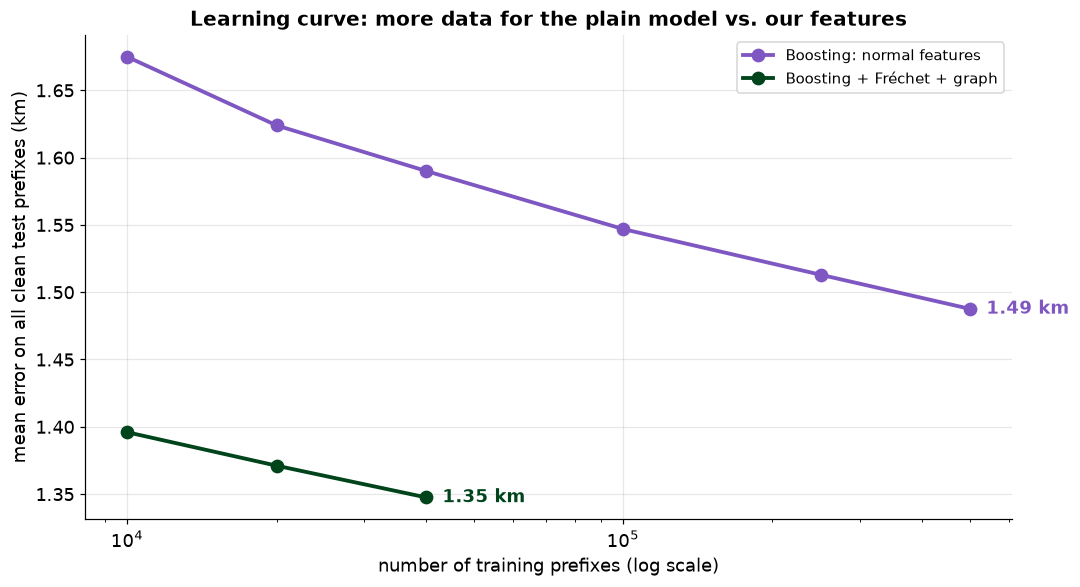

In [14]:
def curve(X_all, Y_all, X_test, full_name):
    sizes = sorted(set([n for n in LC_SIZES if n < len(X_all)] + [len(X_all)]))
    errs = []
    for n in sizes:
        m = models[full_name] if n == len(X_all) else fit_gbm(X_all[:n], Y_all[:n], SEED)
        p = now_te[clean_mask] + predict(m, X_test[clean_mask])
        errs.append(np.hypot(*(p - true_te[clean_mask]).T).mean())
    return sizes, errs

sizes_n, lc_n = curve(X_big, y_big, X_te[:, :N_NORMAL], BIG)
sizes_f, lc_f = curve(X_tr, y_tr, X_te, BEST)
for name, sizes, errs in [("normal features", sizes_n, lc_n), ("+ Fréchet & graph", sizes_f, lc_f)]:
    print(f"  {name:<18}" + "  ".join(f"{n:,}: {e:.3f} km" for n, e in zip(sizes, errs)))

fig, ax = plt.subplots(figsize=(10, 5.5))
for sizes, errs, c, lab in [(sizes_n, lc_n, COLOR[BIG], "Boosting: normal features"),
                            (sizes_f, lc_f, COLOR[BEST], "Boosting + Fréchet + graph")]:
    ax.plot(sizes, errs, "-o", lw=2.5, ms=8, color=c, label=lab)
    ax.text(sizes[-1] * 1.08, errs[-1], f"{errs[-1]:.2f} km", va="center", color=c, fontweight="bold")
ax.set_xscale("log"); ax.set_xlabel("number of training prefixes (log scale)")
ax.set_ylabel("mean error on all clean test prefixes (km)")
ax.set_title("Learning curve: more data for the plain model vs. our features"); ax.legend()
plt.tight_layout(); save(fig, "08_learning_curve")

## 15. Results table with 95% bootstrap intervals
The test trips are drawn again *with replacement* 1000 times; the middle 95% of the recomputed numbers is the
interval. Mean, median (typical trip), 90th percentile (bad cases) and share of guesses within 1 km.

In [15]:
boot_rng = stream(4)
STAT = {"mean": np.mean, "median": np.median, "p90": lambda x, axis=None: np.percentile(x, 90, axis=axis)}

def summarise(frame):
    out = []
    for (method, setting), g in frame.groupby(["method", "setting"]):
        e = g.err_km.values
        picks = boot_rng.integers(0, len(e), size=(N_BOOT, len(e)))
        row = dict(method=method, setting=setting, n=len(g), within_1km=np.mean(e <= 1.0))
        for name, f in STAT.items():
            again = f(e[picks], axis=1)
            row.update({name: f(e), f"{name}_low": np.percentile(again, 2.5), f"{name}_high": np.percentile(again, 97.5)})
        out.append(row)
    return pd.DataFrame(out)

clean, noisy = res[res.group == "clean"], res[res.group == "noisy"]
summary, summary_noisy = summarise(clean), summarise(noisy)

def value(method, setting, col, table_=None):
    t = summary if table_ is None else table_
    return t[(t.method == method) & (t.setting == setting)][col].iloc[0]

for s in SETTINGS:
    t = summary[summary.setting == s].sort_values("mean")
    print(f"\n========== {SAW[s]} ==========")
    print(pd.DataFrame({
        "method": [NICE[m] for m in t.method], "trips": t.n,
        "mean km [95%]": [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(t["mean"], t.mean_low, t.mean_high)],
        "median km [95%]": [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(t["median"], t.median_low, t.median_high)],
        "p90 km": [f"{a:.2f}" for a in t["p90"]],
        "within 1 km": [f"{a:.0%}" for a in t.within_1km]}).to_string(index=False))


========== saw 25% of the trip ==========
                                  method  trips        mean km [95%]      median km [95%] p90 km within 1 km
              Boosting + Fréchet + graph  10000 2.037 [1.997, 2.081] 1.371 [1.343, 1.402]   4.39         37%
         Random Forest + Fréchet + graph  10000 2.056 [2.011, 2.101] 1.389 [1.358, 1.420]   4.41         36%
            Boosting + Fréchet, no graph  10000 2.124 [2.081, 2.167] 1.440 [1.409, 1.473]   4.56         35%
Boosting: normal features, 500k prefixes  10000 2.162 [2.118, 2.203] 1.490 [1.459, 1.528]   4.59         32%
       Fréchet + offset + graph (clique)  10000 2.187 [2.143, 2.231] 1.508 [1.479, 1.539]   4.52         33%
                    DTW (adds distances)    500 2.200 [2.024, 2.383] 1.576 [1.460, 1.797]   4.48         28%
                        Fréchet + offset  10000 2.228 [2.189, 2.271] 1.627 [1.598, 1.662]   4.60         29%
       Fréchet neighbours: plain average  10000 2.230 [2.188, 2.270] 1.628 [1.594, 1.

## 16. Is a difference real? Paired bootstrap + report card
Both methods are scored on **exactly the same** trips; we bootstrap the difference A − B. If its whole 95%
interval is above 0, B is really better; if it contains 0, we cannot say. Gains under 25 m are marked negligible.

In [16]:
def errors(method, setting, group="clean"):
    g = res[(res.method == method) & (res.setting == setting) & (res.group == group)]
    return g.set_index("trip").err_km if len(g) else None

def compare(a, b, setting, stat, group="clean"):
    A, B = errors(a, setting, group), errors(b, setting, group)
    if A is None or B is None:
        return None
    both = A.index.intersection(B.index)
    A, B = A.loc[both].values, B.loc[both].values
    picks = boot_rng.integers(0, len(A), size=(N_BOOT, len(A)))
    sa, sb = STAT[stat](A[picks], axis=1), STAT[stat](B[picks], axis=1)
    low, high = np.percentile(sa - sb, [2.5, 97.5])
    diff = STAT[stat](A) - STAT[stat](B)
    return dict(A=a, B=b, setting=setting, stat=stat, n=len(both), a=STAT[stat](A), b=STAT[stat](B),
                a_low=np.percentile(sa, 2.5), a_high=np.percentile(sa, 97.5),
                b_low=np.percentile(sb, 2.5), b_high=np.percentile(sb, 97.5), diff=diff,
                verdict="better" if low > 0 else ("worse" if high < 0 else "same"),
                negligible=abs(diff) * 1000 < PRACTICAL_M)

CLAIMS = [  # (old way, new way, statistic, question)
    ("GBM (normal features)", BEST, "mean", "Do Fréchet + graph features improve the boosting model?"),
    (BIG, BEST, "mean", f"Still better when the plain model gets {len(X_big)/len(X_tr):.0f}x more training data?"),
    (NO_GRAPH, BEST, "mean", "Do the graph (clique) features add anything on top of the Fréchet features?"),
    ("RF (normal features)", "RF + Fréchet + graph features", "mean", "Do Fréchet + graph features improve the Random Forest?"),
    ("prefix-DFD (mean)", "prefix-DFD + offset + graph", "median", "Is the clique better than a plain average? (typical trip)"),
    ("prefix-DFD (mean)", "prefix-DFD + offset + graph", "mean", "Is the clique better than a plain average? (all trips)"),
    ("prefix-DFD (mean)", "prefix-DFD + offset", "mean", "Does the offset help? (Lemma C says: only a little)"),
    ("stay (current point)", BEST, "mean", "Is our best model better than 'it stops where it is now'?"),
    ("lock-step (mean)", "prefix-DFD (mean)", "mean", "Does allowing to wait (Fréchet) beat no waiting (lock-step)?"),
    ("full DFD (mean)", "prefix-DFD (mean)", "mean", "Is matching only the BEGINNING of old trips better than the whole trip?"),
    ("prefix DTW (mean)", "prefix-DFD (mean)", "mean", "Fréchet (longest leash) vs. DTW (sum of all leashes)"),
]
tests = pd.DataFrame([t for a, b, st, _ in CLAIMS for s in SETTINGS if (t := compare(a, b, s, st)) is not None])

def mark(t):
    if t["verdict"] == "same":
        return "= no clear difference"
    word = "✓ new is better" if t["verdict"] == "better" else "✗ old is better"
    return word + (" (negligible, < 25 m)" if t["negligible"] else "")

work = pd.DataFrame(work_rows, columns=["method", "setting", "looked_at", "removed_by_L2", "dp_started", "dp_stopped_L3"])
work = work.groupby(["method", "setting"]).mean()
DP_MEAN = work.xs("prefix-DFD", level="method")["dp_started"].mean()
print("REPORT CARD")
print(f"  ✓ exact search over {N_TRAIN:,} old trips: the DP ran on only {DP_MEAN:,.0f} of them per question "
      f"({100 * DP_MEAN / N_TRAIN:.2f}%); {FAST_MS:.1f} ms per question (median, one core); search {SEARCH_MIN:.1f} min")
print("  ✓ all tests passed (DP, Lemma A, L1–L4, Lemma B, Lemma C, grid search, clique == networkx)")
for a, b, st, q in CLAIMS:
    print(f"\n  {q}   [{st} error]")
    for _, r in tests[(tests.A == a) & (tests.B == b) & (tests.stat == st)].iterrows():
        print(f"      {SAW[r.setting]:<27} {mark(r):<44} (difference {r['diff']*1000:+.0f} m, n = {r.n:,})")

REPORT CARD
  ✓ exact search over 1,223,042 old trips: the DP ran on only 1,315 of them per question (0.11%); 6.3 ms per question (median, one core); search 5.3 min
  ✓ all tests passed (DP, Lemma A, L1–L4, Lemma B, Lemma C, grid search, clique == networkx)

  Do Fréchet + graph features improve the boosting model?   [mean error]
      saw 25% of the trip         ✓ new is better                              (difference +252 m, n = 10,000)
      saw 50% of the trip         ✓ new is better                              (difference +191 m, n = 10,000)
      saw 75% of the trip         ✓ new is better                              (difference +303 m, n = 10,000)
      random cut point (10–90%)   ✓ new is better                              (difference +243 m, n = 10,000)

  Still better when the plain model gets 12x more training data?   [mean error]
      saw 25% of the trip         ✓ new is better                              (difference +125 m, n = 10,000)
      saw 50% of the trip       

## 17. Robustness: trips WITH a GPS glitch
These trips were never used for learning or tuning.

In [17]:
for s in FIXED:
    print(f"\n{SAW[s]}  (clean mean km -> noisy mean km)")
    for m in ["stay (current point)", BIG, "prefix-DFD (mean)", "prefix-DFD + offset + graph", BEST]:
        print(f"   {NICE[m]:<42} {value(m, s, 'mean'):.3f} -> {value(m, s, 'mean', summary_noisy):.3f}")
    t = compare(BIG, BEST, s, "mean", group="noisy")
    print(f"   noisy trips, our features vs. big-data plain model: {mark(t)} (difference {t['diff']*1000:+.0f} m)")


saw 25% of the trip  (clean mean km -> noisy mean km)
   Stay: it stops where it is now             2.968 -> 3.980
   Boosting: normal features, 500k prefixes   2.162 -> 3.330
   Fréchet neighbours: plain average          2.230 -> 3.335
   Fréchet + offset + graph (clique)          2.187 -> 3.385
   Boosting + Fréchet + graph                 2.037 -> 3.245
   noisy trips, our features vs. big-data plain model: ✓ new is better (difference +84 m)

saw 50% of the trip  (clean mean km -> noisy mean km)
   Stay: it stops where it is now             2.000 -> 2.841
   Boosting: normal features, 500k prefixes   1.396 -> 2.008
   Fréchet neighbours: plain average          1.521 -> 2.202
   Fréchet + offset + graph (clique)          1.414 -> 2.106
   Boosting + Fréchet + graph                 1.303 -> 2.031
   noisy trips, our features vs. big-data plain model: = no clear difference (difference -23 m)

saw 75% of the trip  (clean mean km -> noisy mean km)
   Stay: it stops where it is now      

# Results in pictures
## 18. Leaderboard: average error of every method (shorter bar = better)

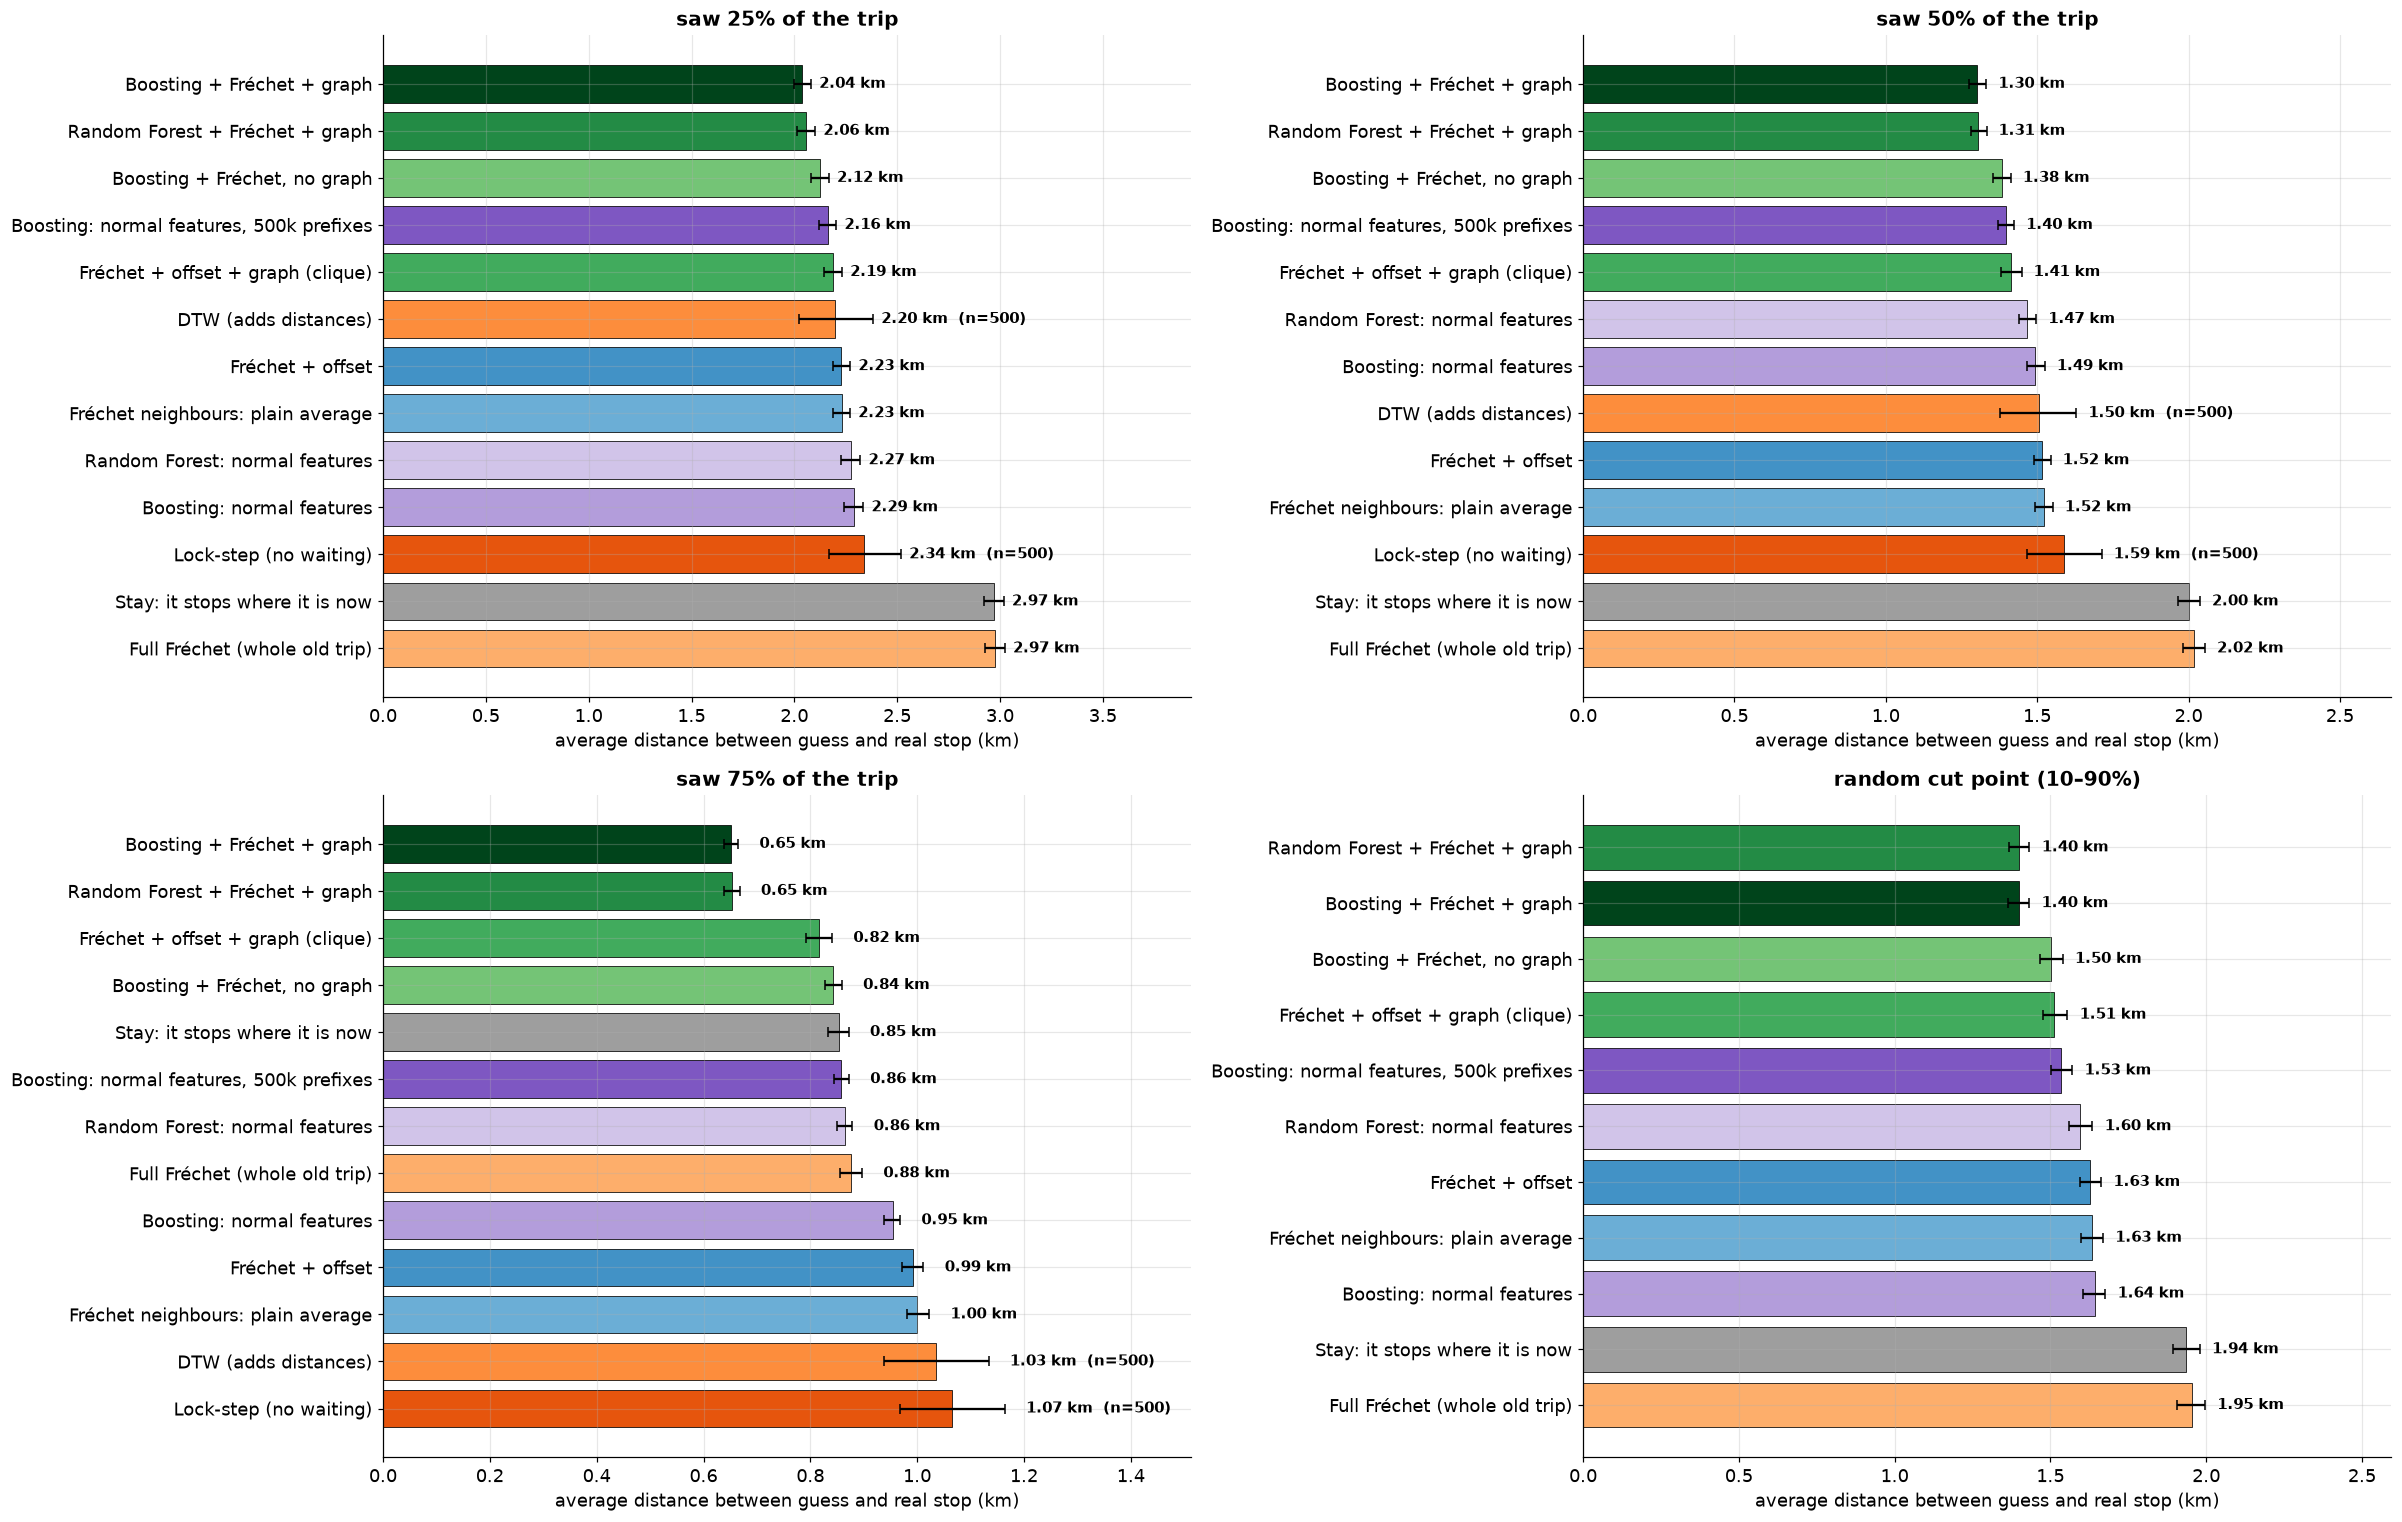

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(22, 14))
for ax, s in zip(axes.ravel(), SETTINGS):
    t = summary[summary.setting == s].sort_values("mean", ascending=False)
    y = np.arange(len(t))
    ax.barh(y, t["mean"], xerr=[t["mean"] - t.mean_low, t.mean_high - t["mean"]], capsize=3,
            color=[COLOR[m] for m in t.method], edgecolor="black", linewidth=0.5)
    for yi, v, hi, n in zip(y, t["mean"], t.mean_high, t.n):
        ax.text(hi + 0.04, yi, f"{v:.2f} km" + ("" if n == t.n.max() else f"  (n={n:,})"), va="center",
                fontsize=10, fontweight="bold")
    ax.set_xlim(0, t.mean_high.max() * 1.3)
    ax.set_yticks(y, [NICE[m] for m in t.method]); ax.set_title(SAW[s])
    ax.set_xlabel("average distance between guess and real stop (km)")
plt.tight_layout(); save(fig, "03_leaderboard")

## 19. Head-to-head answers to the report-card questions
Grey = the old / simple way, green = the new way, computed on exactly the same trips (black line = 95% interval).

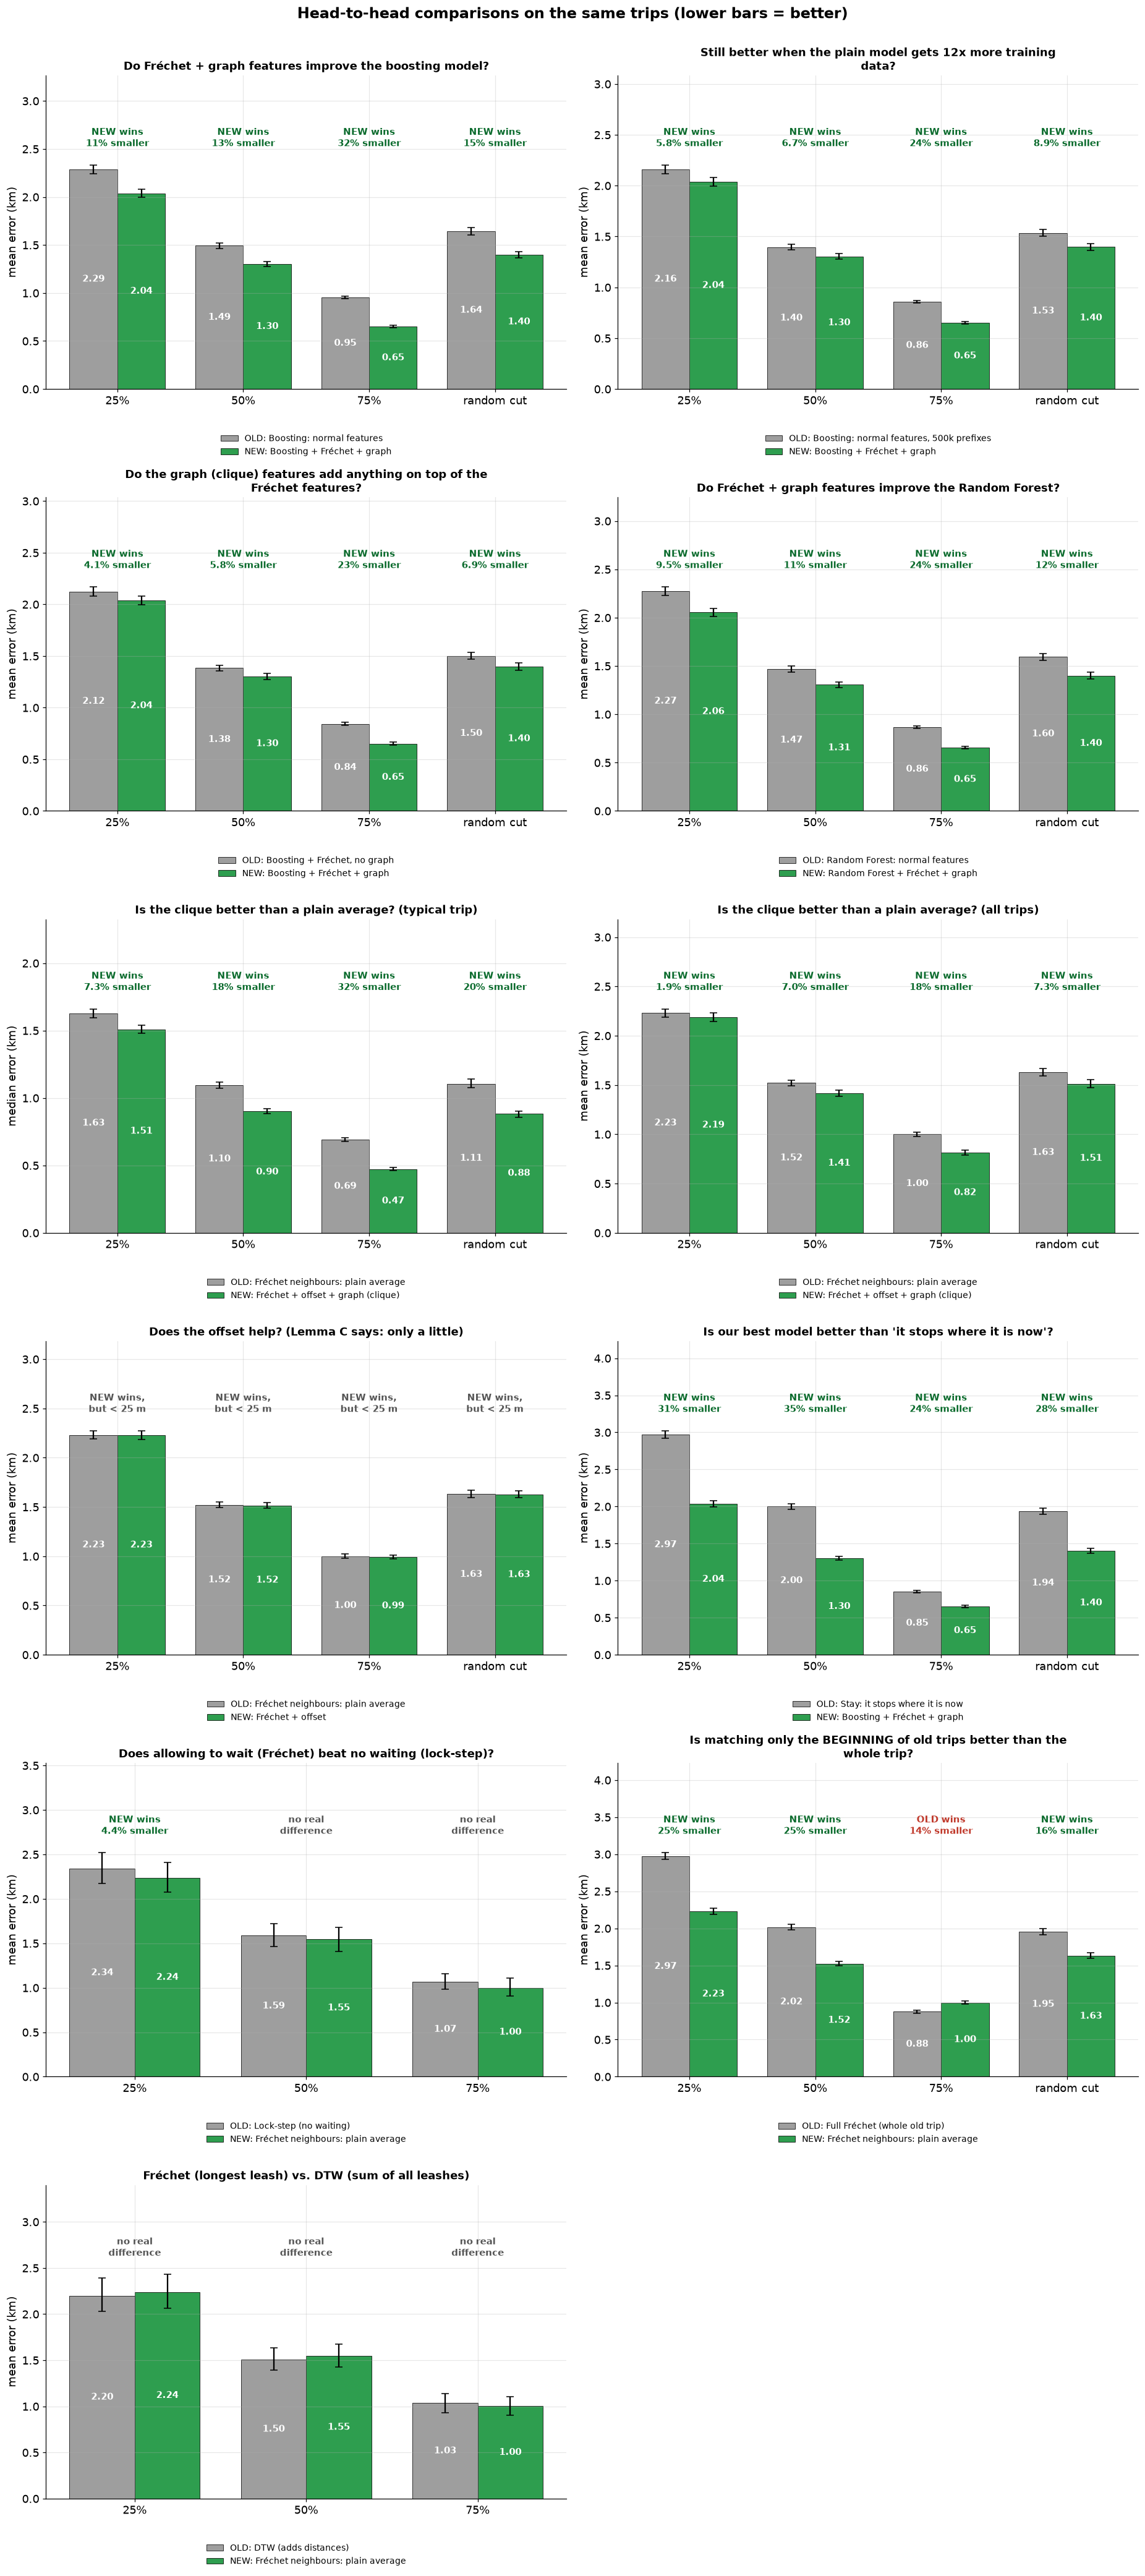

In [19]:
def head_to_head(ax, a, b, stat, question):
    t = tests[(tests.A == a) & (tests.B == b) & (tests.stat == stat)].set_index("setting")
    sets = [s for s in SETTINGS if s in t.index]
    x, w = np.arange(len(sets)), 0.38
    top = 0
    for k, (col, colr, who, m) in enumerate([("a", "#9e9e9e", "OLD: ", a), ("b", "#2e9e4f", "NEW: ", b)]):
        v, lo, hi = t.loc[sets, col], t.loc[sets, f"{col}_low"], t.loc[sets, f"{col}_high"]
        ax.bar(x + (k - 0.5) * w, v, w, yerr=[v - lo, hi - v], capsize=4, color=colr,
               edgecolor="black", linewidth=0.5, label=who + NICE[m])
        for xi, vi in zip(x + (k - 0.5) * w, v):
            ax.text(xi, vi / 2, f"{vi:.2f}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
        top = max(top, hi.max())
    for i, s in enumerate(sets):
        r = t.loc[s]
        pct = 100 * (r.a - r.b) / r.a
        p = f"{abs(pct):.1f}" if abs(pct) < 10 else f"{abs(pct):.0f}"
        if r.verdict == "same":
            text, colr = "no real\ndifference", "#555555"
        elif r.negligible:
            text, colr = f"{'NEW' if r.verdict == 'better' else 'OLD'} wins,\nbut < 25 m", "#555555"
        elif r.verdict == "better":
            text, colr = f"NEW wins\n{p}% smaller", "#0b6b2d"
        else:
            text, colr = f"OLD wins\n{p}% smaller", "#c0392b"
        ax.text(i, top * 1.07, text, ha="center", va="bottom", color=colr, fontweight="bold", fontsize=10)
    ax.set_ylim(0, top * 1.4)
    ax.set_xticks(x, [s if s != "random" else "random cut" for s in sets])
    ax.set_ylabel(f"{stat} error (km)"); ax.set_title(textwrap.fill(question, 60), fontsize=12)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, fontsize=9, frameon=False)

n_rows = (len(CLAIMS) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(17, 6.3 * n_rows))
for ax, (a, b, st, q) in zip(axes.ravel(), CLAIMS):
    head_to_head(ax, a, b, st, q)
for ax in axes.ravel()[len(CLAIMS):]:
    ax.axis("off")
fig.suptitle("Head-to-head comparisons on the same trips (lower bars = better)", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout(); save(fig, "04_head_to_head")

## 20. Speed: how the lower bounds save work
Left: time per question (one core). Middle: share of the 1.2M old trips each distance has to look at.
Right: how the old trips are filtered step by step (prefix Fréchet, 50% seen).

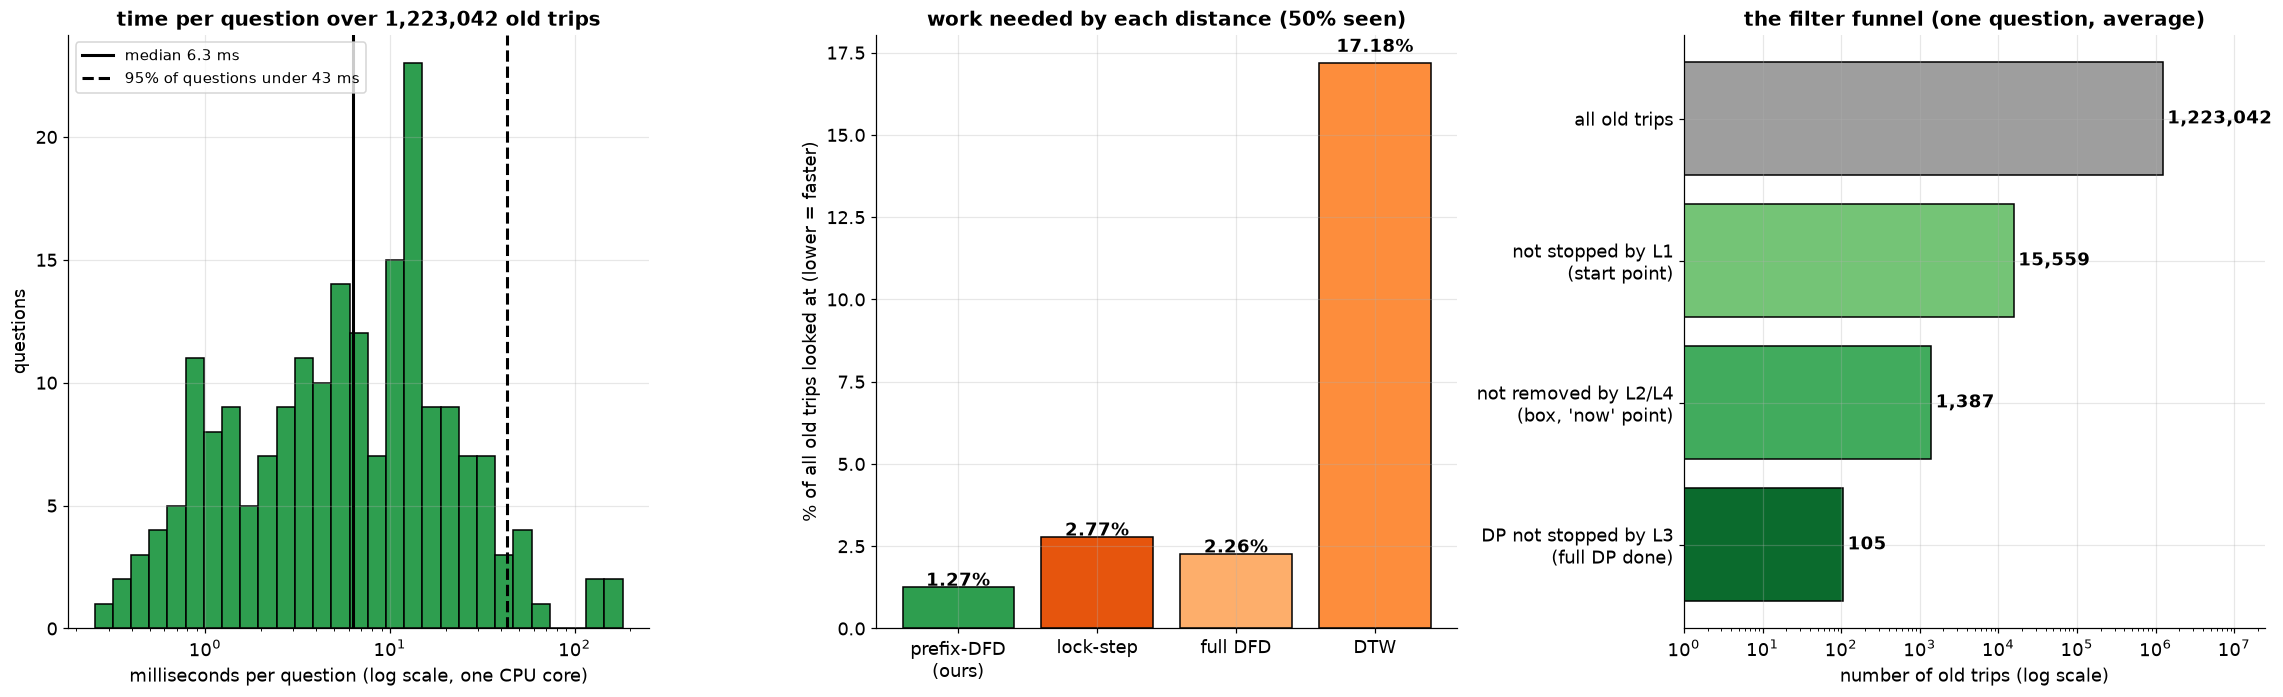

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
axes[0].hist(fast_ms, bins=np.logspace(np.log10(max(fast_ms.min(), 0.1)), np.log10(fast_ms.max() + 1), 30),
             color="#2e9e4f", edgecolor="black")
axes[0].set_xscale("log")
axes[0].axvline(FAST_MS, color="black", lw=2, label=f"median {FAST_MS:.1f} ms")
axes[0].axvline(FAST_P95, color="black", lw=2, ls="--", label=f"95% of questions under {FAST_P95:.0f} ms")
axes[0].set_xlabel("milliseconds per question (log scale, one CPU core)"); axes[0].set_ylabel("questions")
axes[0].set_title(f"time per question over {N_TRAIN:,} old trips"); axes[0].legend()

names = [n for n in ["prefix-DFD", "lock-step", "full DFD", "prefix DTW"] if (n, "50%") in work.index]
shares = [100 * work.loc[(n, "50%"), "looked_at"] / N_TRAIN for n in names]
bars = axes[1].bar([n.replace("prefix-DFD", "prefix-DFD\n(ours)").replace("prefix DTW", "DTW") for n in names], shares,
                   color=[{"prefix-DFD": "#2e9e4f", "lock-step": "#e6550d", "full DFD": "#fdae6b",
                           "prefix DTW": "#fd8d3c"}[n] for n in names], edgecolor="black")
for b_, v in zip(bars, shares):
    axes[1].text(b_.get_x() + b_.get_width() / 2, v * 1.02, f"{v:.2f}%", ha="center", fontweight="bold")
axes[1].set_ylabel("% of all old trips looked at (lower = faster)")
axes[1].set_title("work needed by each distance (50% seen)")

w_ = work.loc[("prefix-DFD", "50%")]
steps = [("all old trips", N_TRAIN), ("not stopped by L1\n(start point)", w_.looked_at),
         ("not removed by L2/L4\n(box, 'now' point)", w_.dp_started), ("DP not stopped by L3\n(full DP done)",
                                                                 w_.dp_started - w_.dp_stopped_L3)]
y = np.arange(len(steps))[::-1]
axes[2].barh(y, [max(v, 1) for _, v in steps], color=["#9e9e9e", "#74c476", "#41ab5d", "#0b6b2d"], edgecolor="black")
for yi, (_, v) in zip(y, steps):
    axes[2].text(max(v, 1) * 1.15, yi, f"{v:,.0f}", va="center", fontweight="bold")
axes[2].set_yticks(y, [n for n, _ in steps]); axes[2].set_xscale("log")
axes[2].set_xlim(1, N_TRAIN * 20); axes[2].set_xlabel("number of old trips (log scale)")
axes[2].set_title("the filter funnel (one question, average)")
plt.tight_layout(); save(fig, "05_speed_and_pruning")

## 21. How r was chosen
Solid = validation (the circle is the chosen r), dashed = the same on 5,000 test prefixes (only to check that
validation was a good guide), dotted = no graph at all.

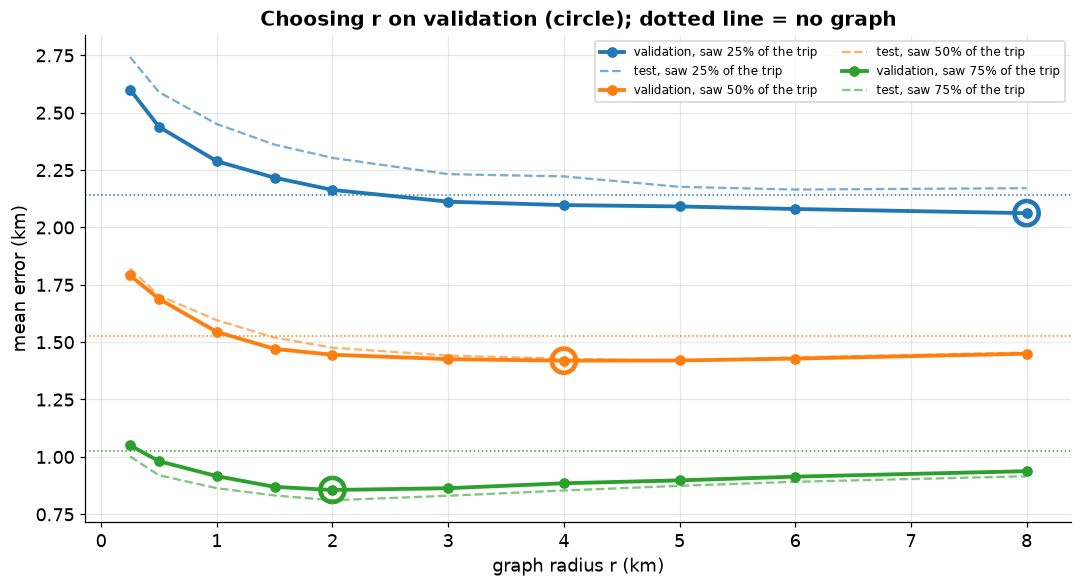

In [21]:
check = [it for it in test_items if it["setting"] in FIXED][:5_000]
test_curve = pd.DataFrame([(it["setting"], r, np.linalg.norm(clique_centre(it["offs"], it["d"], r) - it["true"]))
                           for it in check for r in R_GRID], columns=["setting", "r", "err"]).groupby(["r", "setting"]).err.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 5.5))
for s, colr in zip(FIXED, ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(R_GRID, val_curve.loc[R_GRID, s], "-o", color=colr, lw=2.5, label=f"validation, {SAW[s]}")
    ax.plot(R_GRID, test_curve.loc[R_GRID, s], "--", color=colr, alpha=0.6, label=f"test, {SAW[s]}")
    ax.axhline(val_curve.loc[np.inf, s], color=colr, lw=1, ls=":")
    ax.scatter([R_BEST[s]], [val_curve.loc[R_BEST[s], s]], s=250, facecolors="none", edgecolors=colr, lw=3)
ax.set_xlabel("graph radius r (km)"); ax.set_ylabel("mean error (km)")
ax.set_title("Choosing r on validation (circle); dotted line = no graph"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); save(fig, "06_choosing_r")

## 22. Which features does the best model need? (permutation importance)
We shuffle one feature (or a group) across the test trips and measure how much the mean error grows.

  shuffle all normal features         : error grows by 175 m
  shuffle all Fréchet features        : error grows by 539 m
  shuffle all graph (clique) features : error grows by 396 m


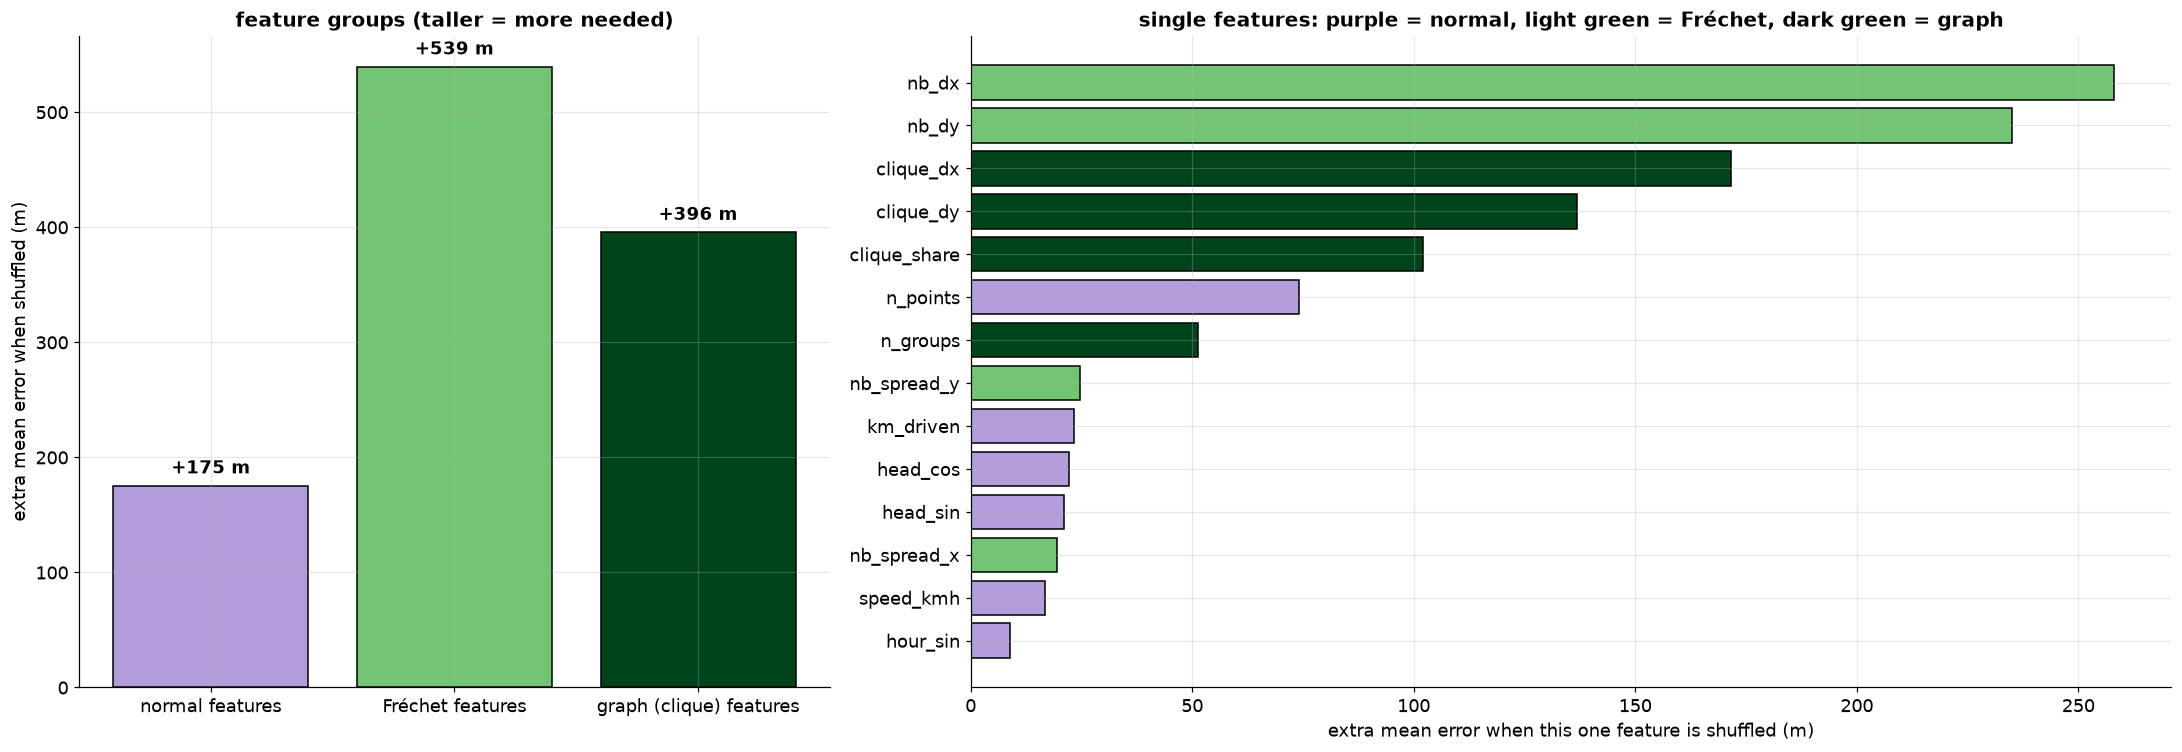

In [22]:
perm_rng = stream(5)
X_clean, now_clean, true_clean = X_te[clean_mask], now_te[clean_mask], true_te[clean_mask]

def mean_err(X):
    return np.hypot(*(now_clean + predict(models[BEST], X) - true_clean).T).mean()

base_err = mean_err(X_clean)
def shuffled_err(cols):
    X = X_clean.copy()
    X[:, cols] = X[perm_rng.permutation(len(X))][:, cols]
    return mean_err(X) - base_err

group_imp = {"normal features": shuffled_err([COLS_ALL.index(f) for f in NORMAL]),
             "Fréchet features": shuffled_err([COLS_ALL.index(f) for f in FRECHET_ONLY]),
             "graph (clique) features": shuffled_err([COLS_ALL.index(f) for f in GRAPH_ONLY])}
single_imp = pd.Series({f: shuffled_err([i]) for i, f in enumerate(COLS_ALL)})
for g, v in group_imp.items():
    print(f"  shuffle all {g:<24}: error grows by {1000 * v:,.0f} m")

GROUP_COLOR = {**{f: "#b39ddb" for f in NORMAL}, **{f: "#74c476" for f in FRECHET_ONLY}, **{f: "#00441b" for f in GRAPH_ONLY}}
fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 1.6]})
gv = [1000 * v for v in group_imp.values()]
bars = axes[0].bar(list(group_imp), gv, color=["#b39ddb", "#74c476", "#00441b"], edgecolor="black")
for b_, v in zip(bars, gv):
    axes[0].text(b_.get_x() + b_.get_width() / 2, v + max(gv) * 0.02, f"+{v:,.0f} m", ha="center", fontweight="bold")
axes[0].set_ylabel("extra mean error when shuffled (m)"); axes[0].set_title("feature groups (taller = more needed)")
top = single_imp.sort_values().tail(14)
axes[1].barh(top.index, 1000 * top.values, color=[GROUP_COLOR[n] for n in top.index], edgecolor="black")
axes[1].set_xlabel("extra mean error when this one feature is shuffled (m)")
axes[1].set_title("single features: purple = normal, light green = Fréchet, dark green = graph")
plt.tight_layout(); save(fig, "07_permutation_importance")

## 23. The graph step by step (one example, 50% seen)
1. the 20 most similar old trips; 2. each guess gets a disk of radius r/2, touching disks are joined
(unit-disk graph); 3. the maximum clique and its centre, compared with the plain average.

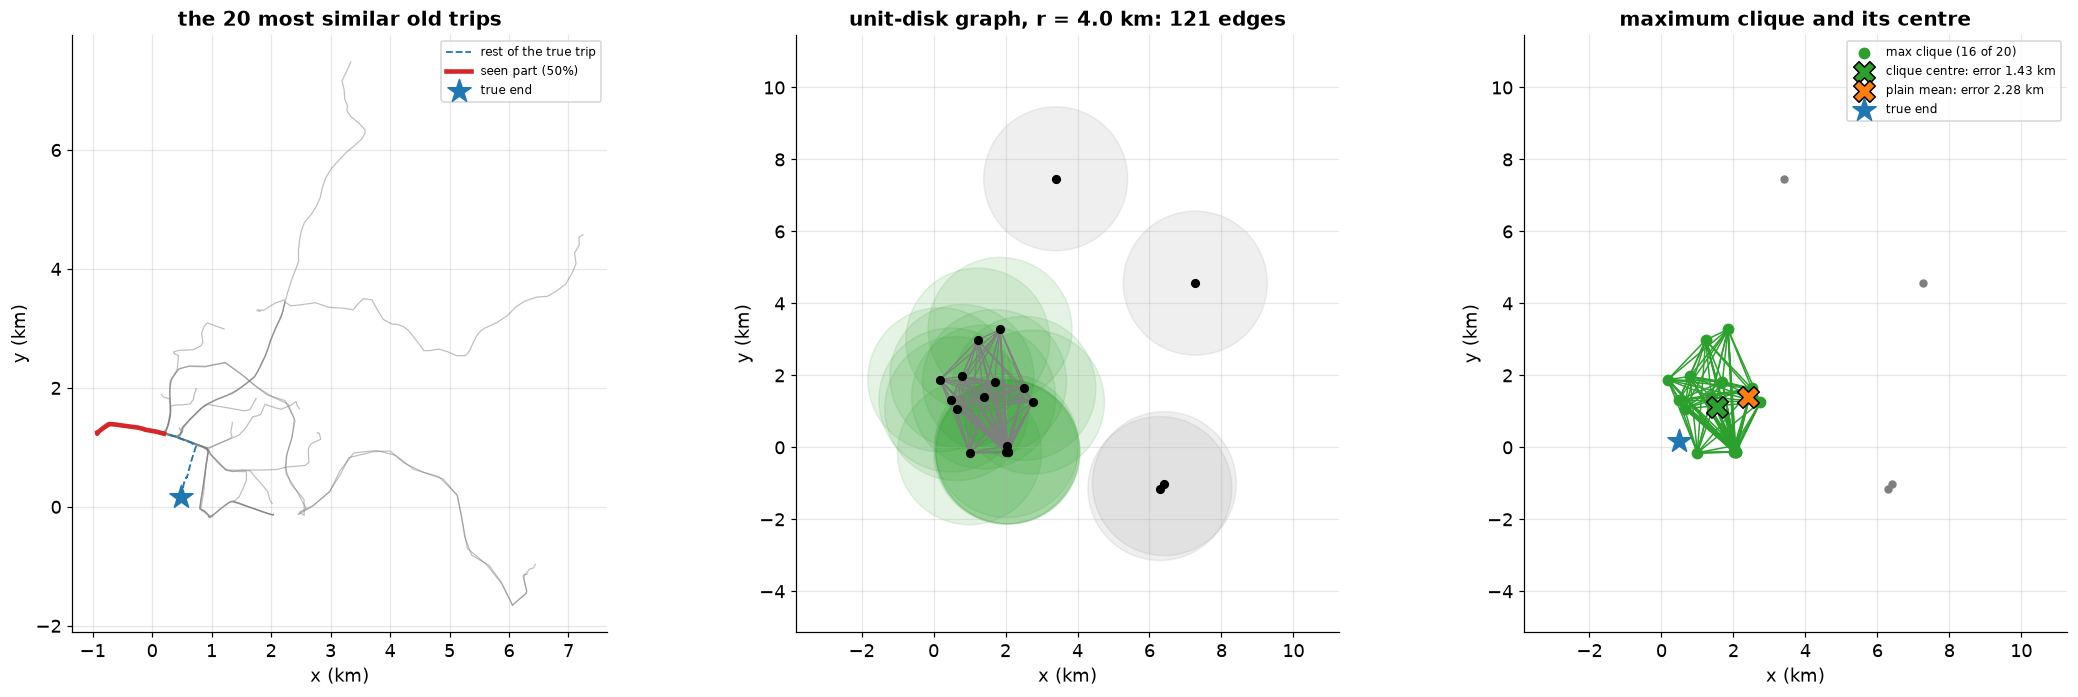

In [23]:
def draw_example(it, r, axes):
    P, true, offs = it["P"], it["true"], it["offs"]
    group, _ = max_clique(offs, it["d"], r)
    G = unit_disk_graph(offs, r)
    centre, mean = offs[group].mean(0), offs.mean(0)
    a0, a1, a2 = axes
    for c in it["ids"]:
        Q = XY[OFF[c]:OFF[c + 1]]
        a0.plot(Q[:, 0], Q[:, 1], color="tab:gray", lw=0.8, alpha=0.5)
    full = trips[it["trip"]]
    a0.plot(full[:, 0], full[:, 1], "--", color="tab:blue", lw=1.2, label="rest of the true trip")
    a0.plot(P[:, 0], P[:, 1], color="tab:red", lw=3, label="seen part (50%)")
    a0.scatter(*true, marker="*", s=250, color="tab:blue", zorder=5, label="true end")
    a0.set_title(f"the {len(offs)} most similar old trips"); a0.legend(fontsize=8)
    for k, p in enumerate(offs):
        a1.add_patch(plt.Circle(p, r / 2, color="tab:green" if k in group else "tab:gray", alpha=0.12))
    for a, b in G.edges():
        a1.plot(*offs[[a, b]].T, color="tab:gray", lw=0.8)
    a1.scatter(*offs.T, s=25, color="black", zorder=3)
    a1.set_title(f"unit-disk graph, r = {r} km: {G.number_of_edges()} edges")
    for a, b in G.edges():
        if a in group and b in group:
            a2.plot(*offs[[a, b]].T, color="tab:green", lw=1)
    a2.scatter(*offs.T, s=20, color="tab:gray")
    a2.scatter(*offs[group].T, s=45, color="tab:green", zorder=3, label=f"max clique ({len(group)} of {len(offs)})")
    a2.scatter(*centre, marker="X", s=200, color="tab:green", edgecolors="k", zorder=5,
               label=f"clique centre: error {np.linalg.norm(centre - true):.2f} km")
    a2.scatter(*mean, marker="X", s=200, color="tab:orange", edgecolors="k", zorder=5,
               label=f"plain mean: error {np.linalg.norm(mean - true):.2f} km")
    a2.scatter(*true, marker="*", s=250, color="tab:blue", zorder=6, label="true end")
    a2.set_title("maximum clique and its centre"); a2.legend(fontsize=8)
    for a in axes:
        a.set_aspect("equal", adjustable="box"); a.set_xlabel("x (km)"); a.set_ylabel("y (km)")
    lo, hi = np.vstack([offs, true[None]]).min(0) - r, np.vstack([offs, true[None]]).max(0) + r
    for a in (a1, a2):
        a.set_xlim(lo[0], hi[0]); a.set_ylim(lo[1], hi[1])

half = [it for it in test_items if it["setting"] == "50%"][:500]
gain = [np.linalg.norm(it["offs"].mean(0) - it["true"]) - np.linalg.norm(it["clique_centre"] - it["true"]) for it in half]
example = half[int(np.argsort(gain)[int(0.9 * (len(gain) - 1))])]     # a clear "graph helps" case
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
draw_example(example, R_BEST["50%"], axes)
plt.tight_layout(); save(fig, "09_clique_step_by_step")

## 24. One-page summary (for slides)

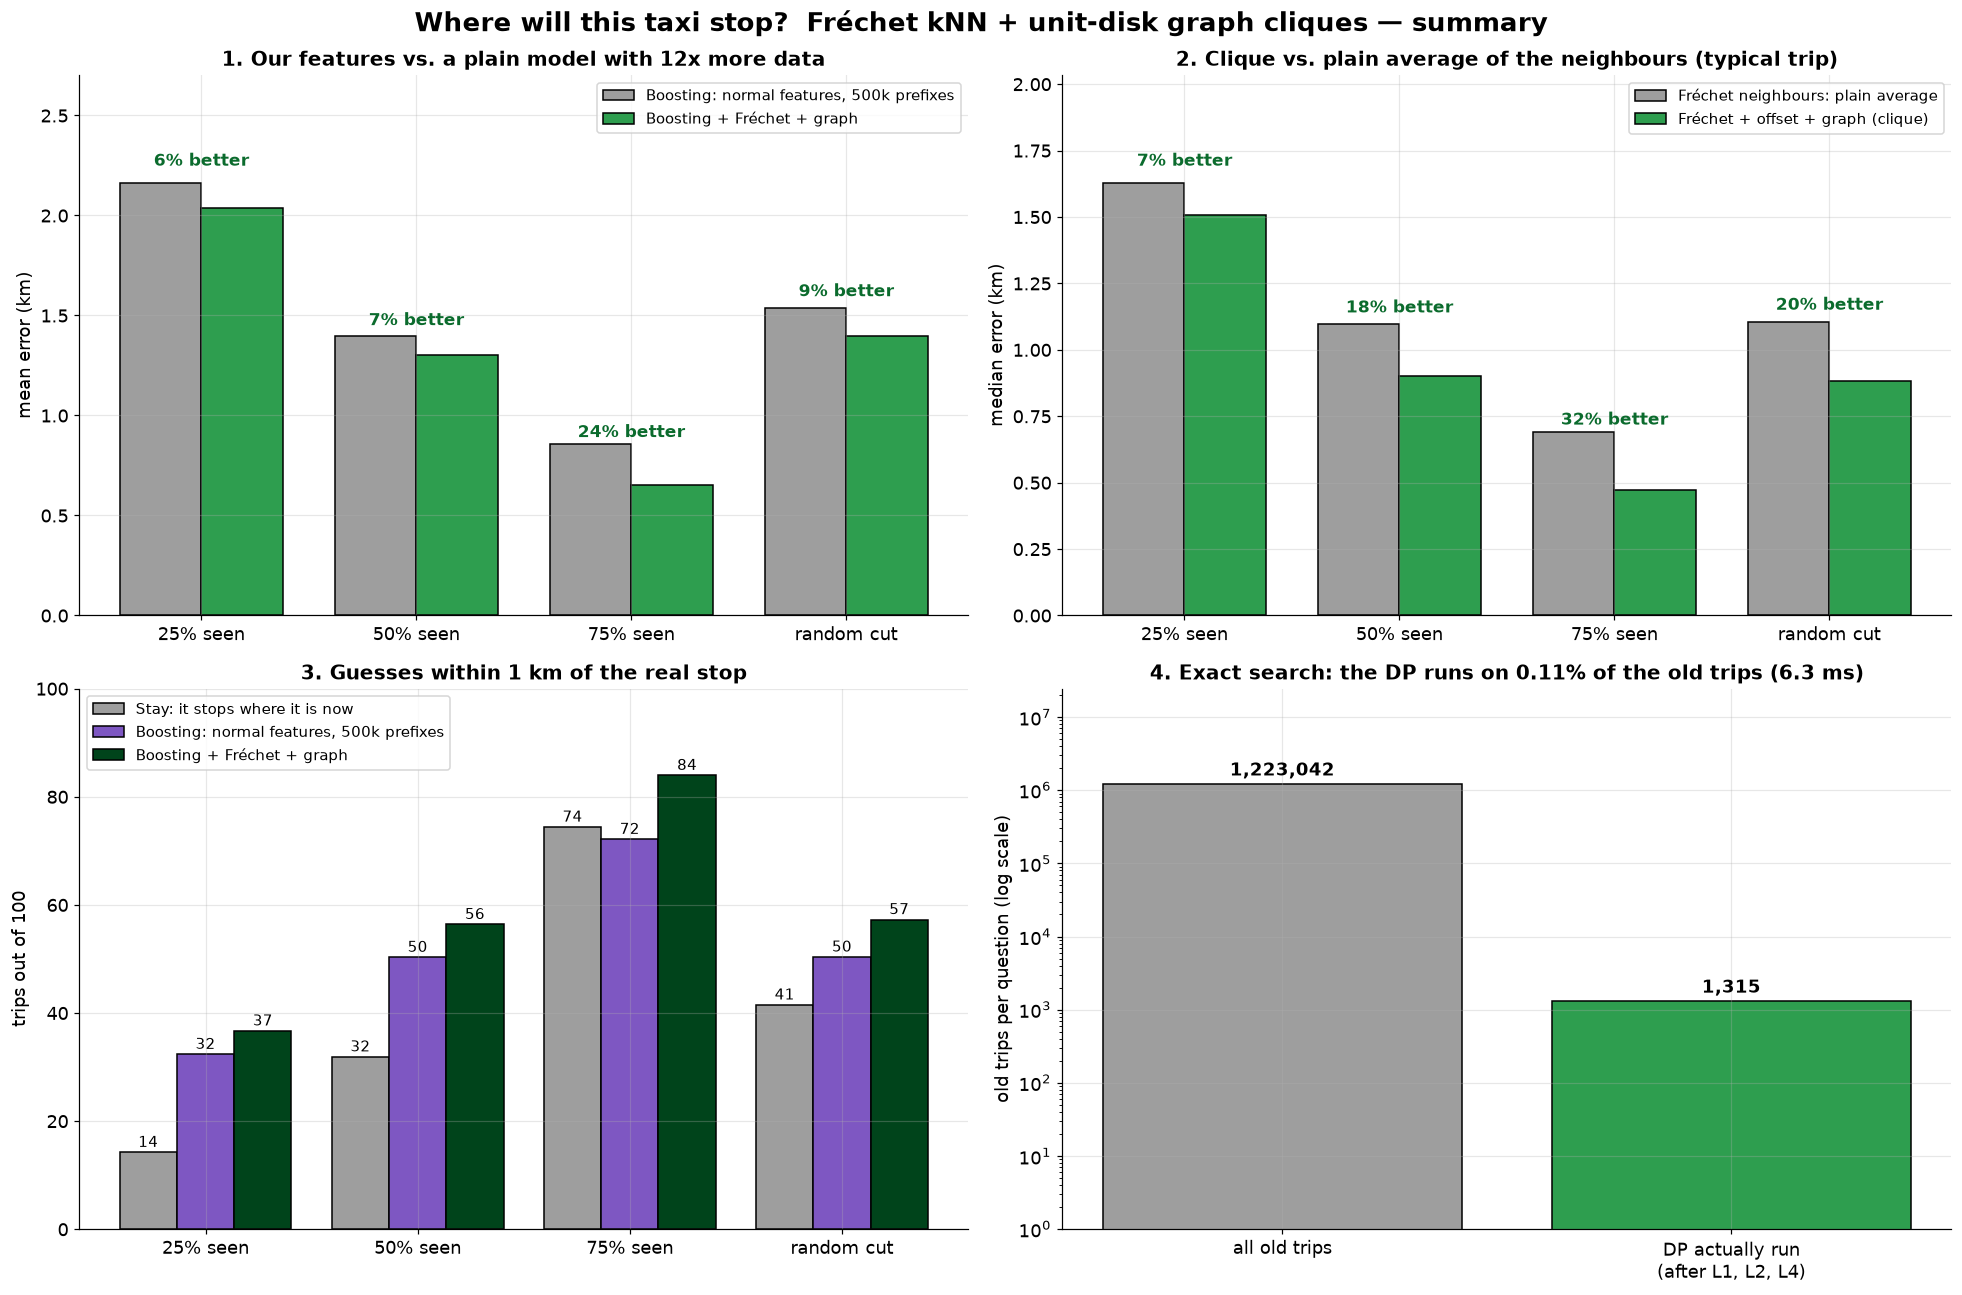

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(18, 12))
x, w = np.arange(len(SETTINGS)), 0.38
labels_x = ["25% seen", "50% seen", "75% seen", "random cut"]

def pair_bars(a_, m_old, m_new, stat, title):
    t = tests[(tests.A == m_old) & (tests.B == m_new) & (tests.stat == stat)].set_index("setting").loc[SETTINGS]
    a_.bar(x - w / 2, t.a, w, color="#9e9e9e", edgecolor="black", label=NICE[m_old])
    a_.bar(x + w / 2, t.b, w, color="#2e9e4f", edgecolor="black", label=NICE[m_new])
    for i, s in enumerate(SETTINGS):
        r = t.loc[s]
        pct = 100 * (r.a - r.b) / r.a
        text, colr = (("no real difference", "#555555") if r.verdict == "same" or r.negligible else
                      (f"{pct:.0f}% better", "#0b6b2d") if r.verdict == "better" else (f"{-pct:.0f}% worse", "#c0392b"))
        a_.text(x[i], max(r.a, r.b) * 1.04, text, ha="center", fontweight="bold", color=colr, fontsize=11)
    a_.set_xticks(x, labels_x); a_.set_ylim(0, t.a.max() * 1.25); a_.set_ylabel(f"{stat} error (km)")
    a_.set_title(title); a_.legend(fontsize=10)

pair_bars(ax[0, 0], BIG, BEST, "mean", f"1. Our features vs. a plain model with {len(X_big)/len(X_tr):.0f}x more data")
pair_bars(ax[0, 1], "prefix-DFD (mean)", "prefix-DFD + offset + graph", "median",
          "2. Clique vs. plain average of the neighbours (typical trip)")
for k, m in enumerate(["stay (current point)", BIG, BEST]):
    v = [100 * value(m, s, "within_1km") for s in SETTINGS]
    bars = ax[1, 0].bar(x + (k - 1) * 0.27, v, 0.27, color=COLOR[m], edgecolor="black", label=NICE[m])
    for b_, h in zip(bars, v):
        ax[1, 0].text(b_.get_x() + b_.get_width() / 2, h + 1, f"{h:.0f}", ha="center", fontsize=10)
ax[1, 0].set_xticks(x, labels_x); ax[1, 0].set_ylim(0, 100); ax[1, 0].legend(fontsize=10)
ax[1, 0].set_ylabel("trips out of 100"); ax[1, 0].set_title("3. Guesses within 1 km of the real stop")
bars = ax[1, 1].bar(["all old trips", "DP actually run\n(after L1, L2, L4)"], [N_TRAIN, DP_MEAN],
                    color=["#9e9e9e", "#2e9e4f"], edgecolor="black")
for b_, v in zip(bars, [N_TRAIN, DP_MEAN]):
    ax[1, 1].text(b_.get_x() + b_.get_width() / 2, v * 1.3, f"{v:,.0f}", ha="center", fontweight="bold")
ax[1, 1].set_yscale("log"); ax[1, 1].set_ylim(1, N_TRAIN * 20); ax[1, 1].set_ylabel("old trips per question (log scale)")
ax[1, 1].set_title(f"4. Exact search: the DP runs on {100 * DP_MEAN / N_TRAIN:.2f}% of the old trips ({FAST_MS:.1f} ms)")
fig.suptitle("Where will this taxi stop?  Fréchet kNN + unit-disk graph cliques — summary", fontsize=17, fontweight="bold")
plt.tight_layout(); save(fig, "00_summary")

## 25. Comparison with the literature, and a Haversine check
The data comes from the **ECML/PKDD 2015 Discovery Challenge**. The winning team (de Brébisson et al., 2015) used
a neural network fed with the first and last 5 GPS points of the known trip plus learned embeddings of the
metadata (client, taxi, stand, time). **Our numbers are not directly comparable**: the challenge scored a small
fixed test set with one random cut point per trip, we use 10,000 trips from the last 15% of the year, we keep
GPS-glitch trips out of training, and we do not use taxi or client IDs. Our *random cut point* results are the
closest analogue. Below: our flat-km error recomputed with the exact Haversine formula on GPS coordinates.

In [25]:
def haversine_km(x1, y1, x2, y2):
    lon1, lat1 = km_to_gps(x1, y1); lon2, lat2 = km_to_gps(x2, y2)
    lon1, lat1, lon2, lat2 = [np.asarray(v) * DEG for v in (lon1, lat1, lon2, lat2)]
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_KM * np.arcsin(np.sqrt(a))

for s in SETTINGS:
    g = clean[(clean.method == BEST) & (clean.setting == s)]
    hv = haversine_km(g.px.values, g.py.values, g.tx.values, g.ty.values)
    print(f"{SAW[s]:<27} best model, mean error: flat {g.err_km.mean():.4f} km | Haversine {hv.mean():.4f} km")

saw 25% of the trip         best model, mean error: flat 2.0375 km | Haversine 2.0372 km
saw 50% of the trip         best model, mean error: flat 1.3027 km | Haversine 1.3025 km
saw 75% of the trip         best model, mean error: flat 0.6512 km | Haversine 0.6512 km
random cut point (10–90%)   best model, mean error: flat 1.3987 km | Haversine 1.3985 km


## 26. Conclusions (generated from the numbers above)

In [26]:
def get(a, b, s, stat="mean"):
    return tests[(tests.A == a) & (tests.B == b) & (tests.stat == stat) & (tests.setting == s)].iloc[0]

def words(t):
    if t.verdict == "same":
        return "no clear difference"
    if t.negligible:
        return "negligible, < 25 m"
    return "clear improvement" if t.verdict == "better" else "clear loss"

def line(a, b, sets=SETTINGS, stat="mean"):
    return "; ".join(f"{s}: {get(a, b, s, stat).a:.2f} -> {get(a, b, s, stat).b:.2f} km "
                     f"({100 * (get(a, b, s, stat).a - get(a, b, s, stat).b) / get(a, b, s, stat).a:+.0f}%, {words(get(a, b, s, stat))})"
                     for s in sets)

noisy_gap = {m: np.mean([value(m, s, "mean", summary_noisy) - value(m, s, "mean") for s in FIXED]) for m in (BIG, BEST)}
out = [
    f"1. EXACT AND FAST: over {N_TRAIN:,} old trips the DP ran on only {DP_MEAN:,.0f} per question "
    f"({100 * DP_MEAN / N_TRAIN:.2f}%); {FAST_MS:.1f} ms per question (median, one core); search for "
    f"{len(val_items) + len(test_items) + len(noisy_items):,} prefixes: {SEARCH_MIN:.1f} min.",
    "2. OUR FEATURES (boosting, same training data): " + line("GBM (normal features)", BEST) + ".",
    f"3. FAIRNESS CHECK (plain model with {len(X_big):,} prefixes vs. ours with {len(X_tr):,}): " + line(BIG, BEST) +
    f". Learning curve: ours with {sizes_f[0]:,} prefixes {lc_f[0]:.2f} km vs. plain with {sizes_n[-1]:,} prefixes {lc_n[-1]:.2f} km.",
    "4. GRAPH FEATURES INSIDE THE MODEL (ablation): " + line(NO_GRAPH, BEST) +
    f". Shuffling the graph features raises the error by {1000 * group_imp['graph (clique) features']:.0f} m.",
    "5. CLIQUE vs. PLAIN AVERAGE (median, no ML): " + line("prefix-DFD (mean)", "prefix-DFD + offset + graph", FIXED, "median") + ".",
    "6. OFFSET: " + "; ".join(f"{s}: {1000 * get('prefix-DFD (mean)', 'prefix-DFD + offset', s)['diff']:+.0f} m" for s in FIXED) +
    f". As Lemma C predicts, the offset moves a guess by at most its Fréchet distance (median move {1000 * np.median(shift):.0f} m).",
    "7. DISTANCE CHOICE (plain average): " + "; ".join(
        f"vs {n}: " + ", ".join(f"{s} {words(get(a, 'prefix-DFD (mean)', s))}" for s in FIXED)
        for a, n in [("lock-step (mean)", "lock-step"), ("full DFD (mean)", "full Fréchet"), ("prefix DTW (mean)", "DTW")]) +
    ". Full Fréchet forces the old trip's END to match the current point, so it behaves like 'stay' early in a trip.",
    f"8. ROBUSTNESS: on trips with a GPS glitch the mean error grows (on average +{noisy_gap[BEST]:.2f} km for our "
    f"model, +{noisy_gap[BIG]:.2f} km for the plain model); our model is "
    + ("still the best on them." if all(value(BEST, s, "mean", summary_noisy) <= summary_noisy[summary_noisy.setting == s]["mean"].min() + 1e-12 for s in FIXED)
       else "not always the best on them (see section 17)."),
    f"9. LIMITS: early in a trip the error is still large (best mean {value(BEST, '25%', 'mean'):.2f} km at 25% seen, "
    f"{100 * value(BEST, '25%', 'within_1km'):.0f}% of guesses within 1 km); taxi and client IDs are not used; "
    "results are not directly comparable with the 2015 challenge leaderboard.",
]
print("\n\n".join(out))
print(f"\ntotal run time {(time.time() - T_START) / 60:.0f} min | pictures in 'figures/': {sorted(os.listdir('figures'))}")

1. EXACT AND FAST: over 1,223,042 old trips the DP ran on only 1,315 per question (0.11%); 6.3 ms per question (median, one core); search for 86,000 prefixes: 5.3 min.

2. OUR FEATURES (boosting, same training data): 25%: 2.29 -> 2.04 km (+11%, clear improvement); 50%: 1.49 -> 1.30 km (+13%, clear improvement); 75%: 0.95 -> 0.65 km (+32%, clear improvement); random: 1.64 -> 1.40 km (+15%, clear improvement).

3. FAIRNESS CHECK (plain model with 500,000 prefixes vs. ours with 40,000): 25%: 2.16 -> 2.04 km (+6%, clear improvement); 50%: 1.40 -> 1.30 km (+7%, clear improvement); 75%: 0.86 -> 0.65 km (+24%, clear improvement); random: 1.53 -> 1.40 km (+9%, clear improvement). Learning curve: ours with 10,000 prefixes 1.40 km vs. plain with 500,000 prefixes 1.49 km.

4. GRAPH FEATURES INSIDE THE MODEL (ablation): 25%: 2.12 -> 2.04 km (+4%, clear improvement); 50%: 1.38 -> 1.30 km (+6%, clear improvement); 75%: 0.84 -> 0.65 km (+23%, clear improvement); random: 1.50 -> 1.40 km (+7%, clear im